# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [5]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [ ]:
#!rm SUSY.csv

In [ ]:
#!gunzip SUSY.csv.gz

In [ ]:
ls -lh

The data is provided as a comma separated file.

In [1]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [ ]:
!ls -lh

We see that we have 5 million datapoints.

In [ ]:
!wc -l SUSY.csv

We create a new file of the first half million. This is sufficient for our needs in this lab:

In [ ]:
!head -500000 SUSY.csv > SUSY-small.csv

In [ ]:
ls -lh

In [ ]:
! wc -l SUSY-small.csv

Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [3]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [4]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [5]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [6]:
FeatureNames

['M_R',
 'S_R',
 'R',
 'MET_rel',
 'M_Delta_R',
 'axial_MET',
 'MT2',
 'M_TR_2',
 'cos_theta_r1',
 'dPhi_r_b']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [8]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [9]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [10]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


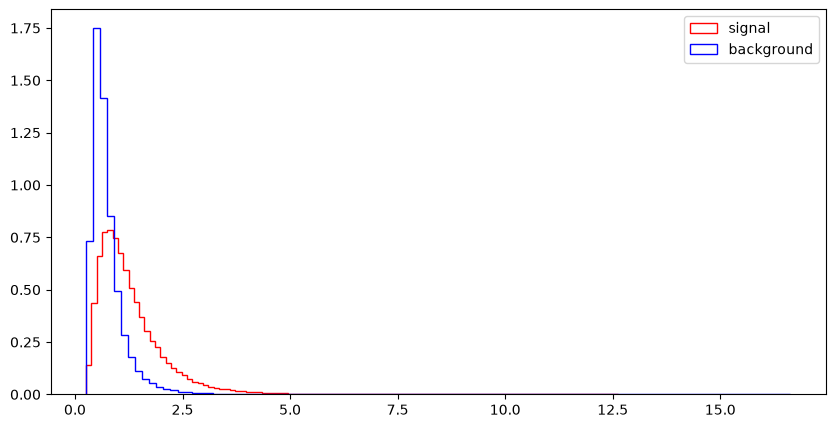

l_1_eta


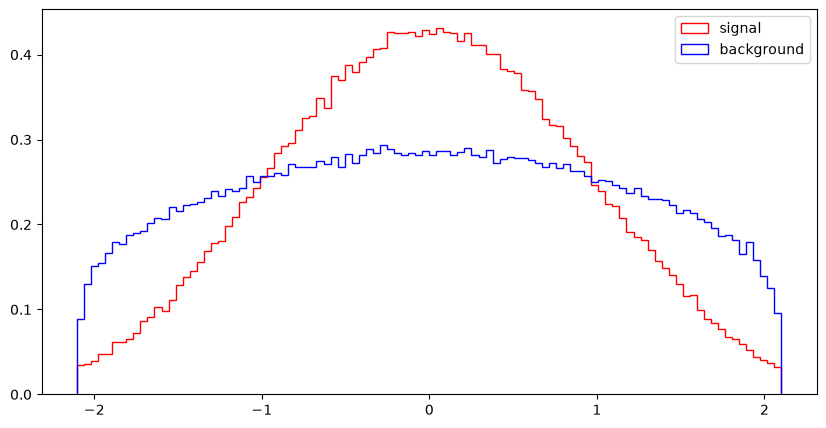

l_1_phi


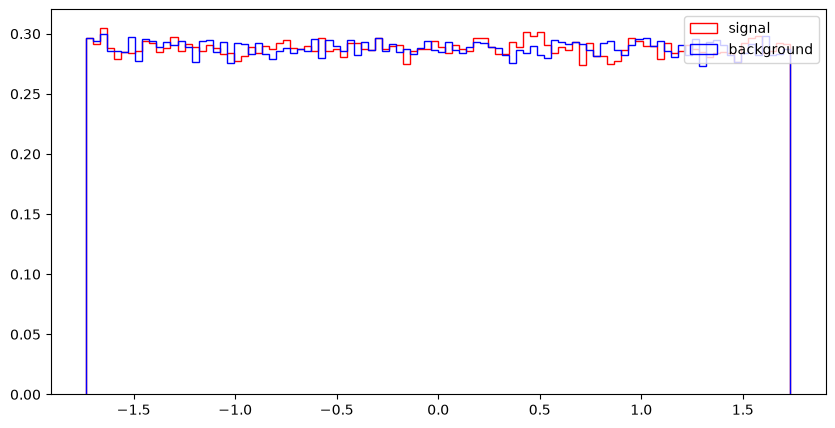

l_2_pT


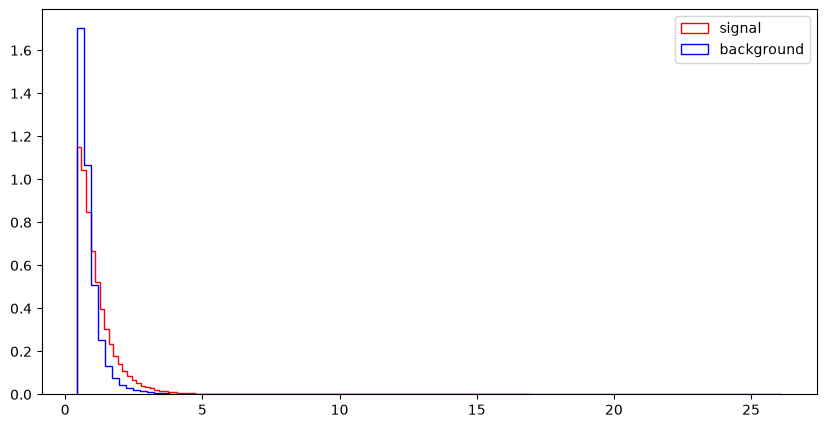

l_2_eta


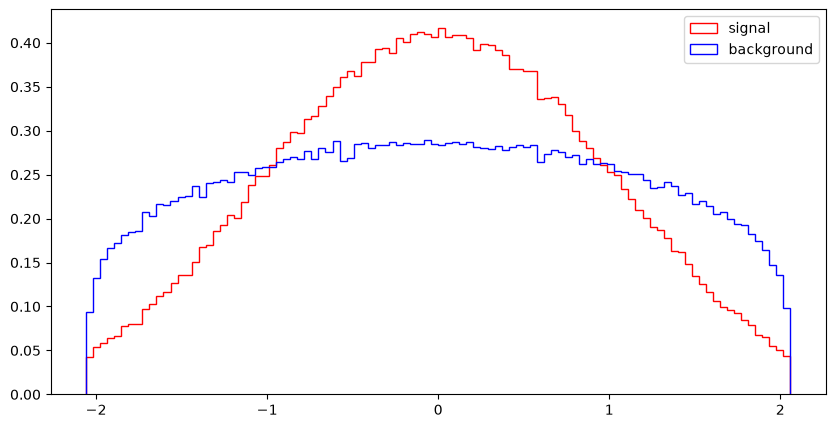

l_2_phi


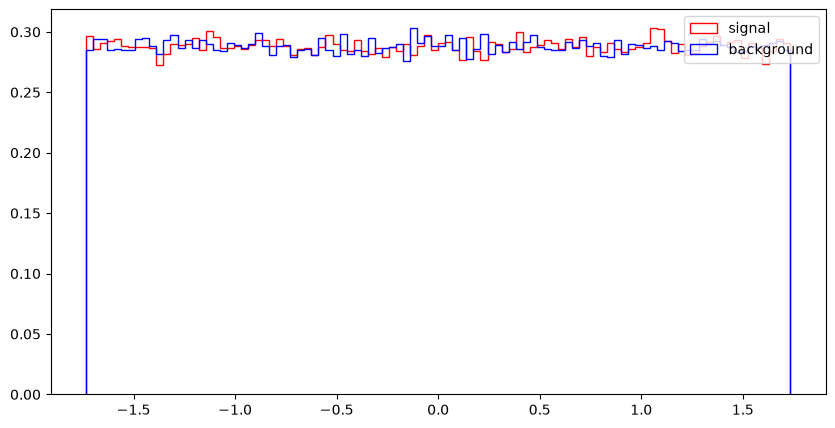

MET


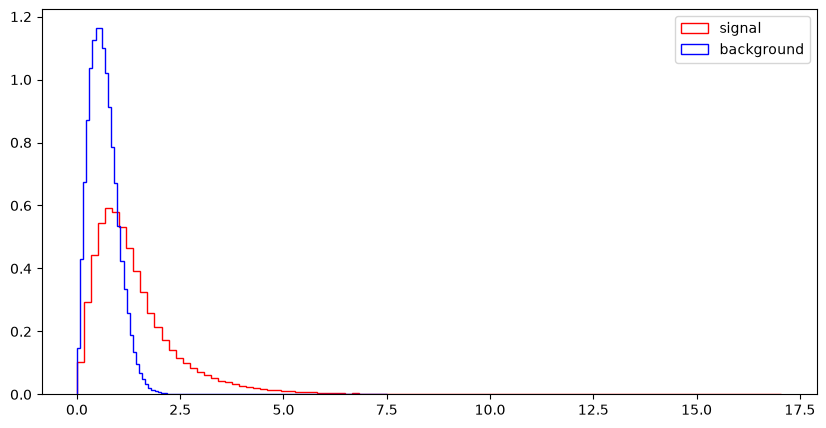

MET_phi


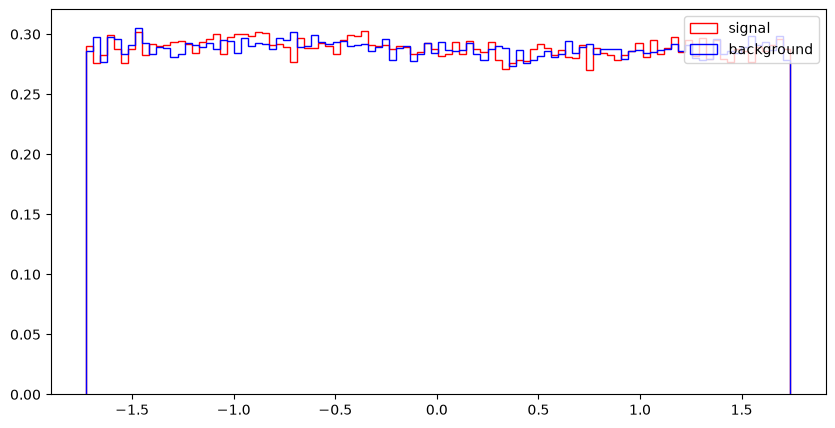

MET_rel


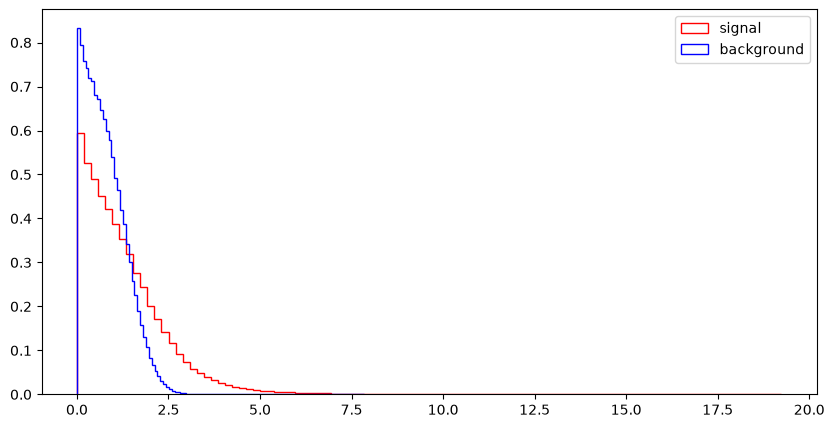

axial_MET


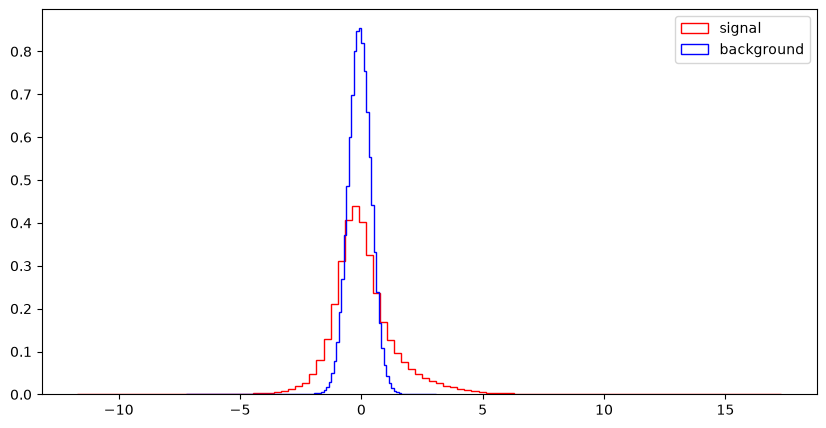

M_R


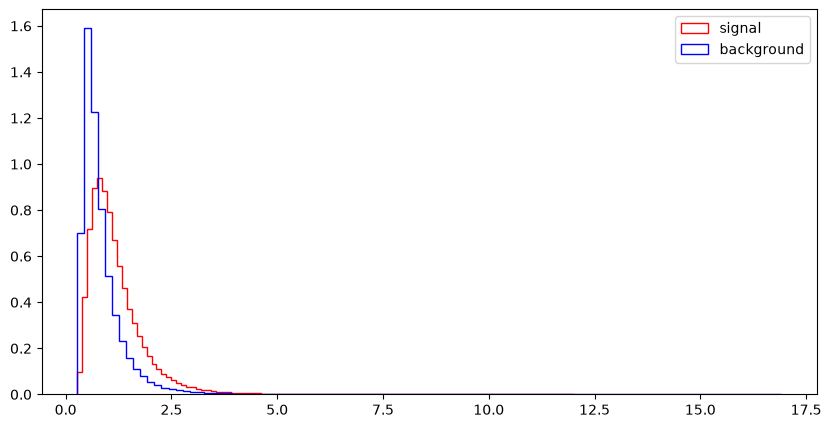

M_TR_2


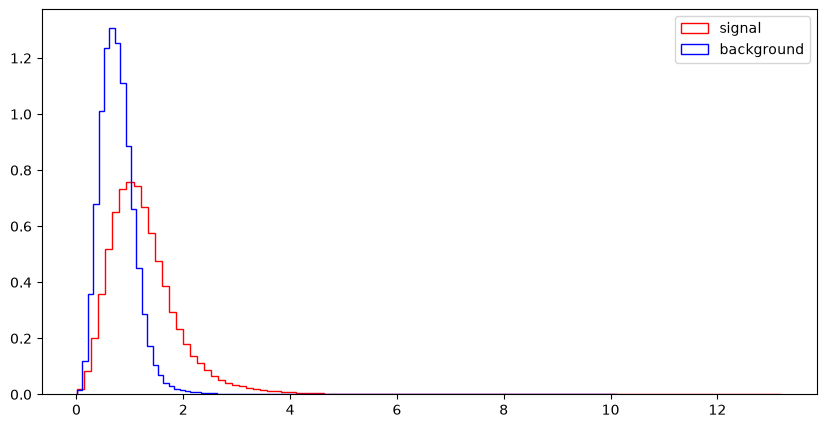

R


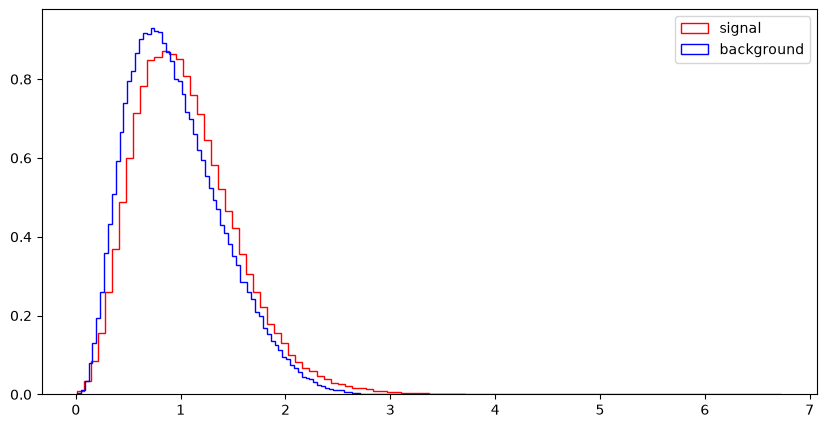

MT2


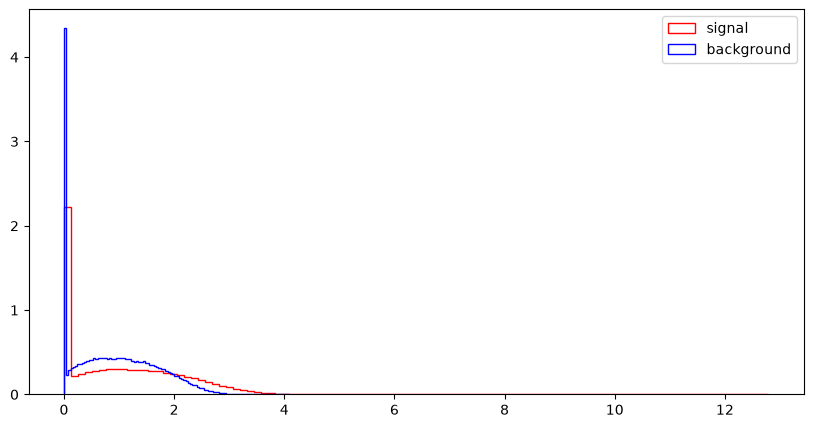

S_R


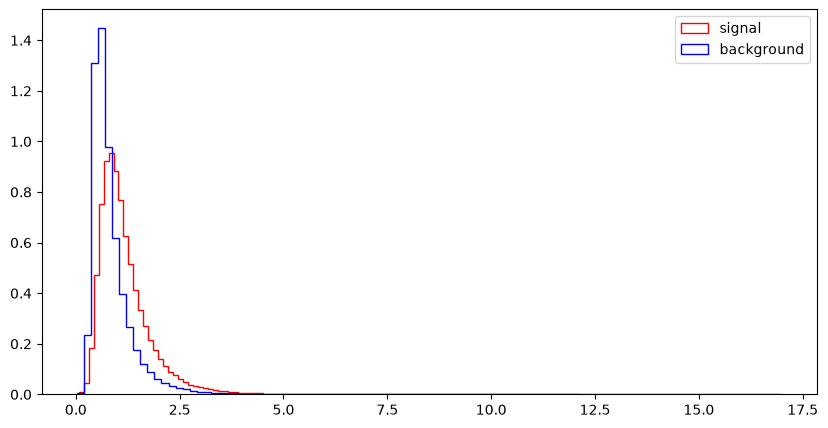

M_Delta_R


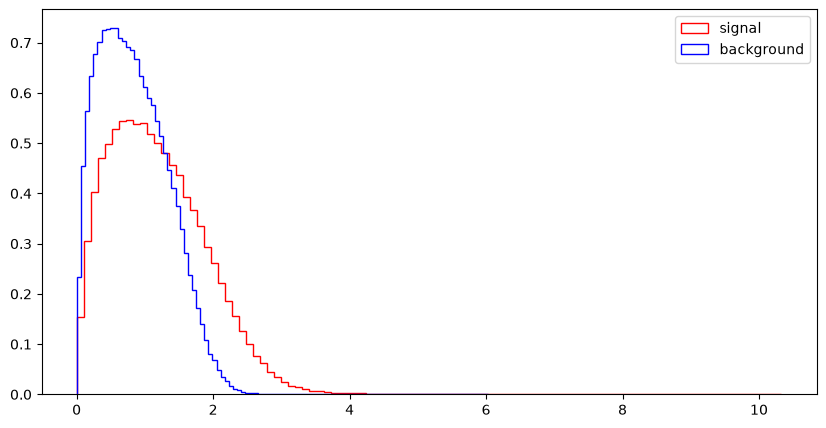

dPhi_r_b


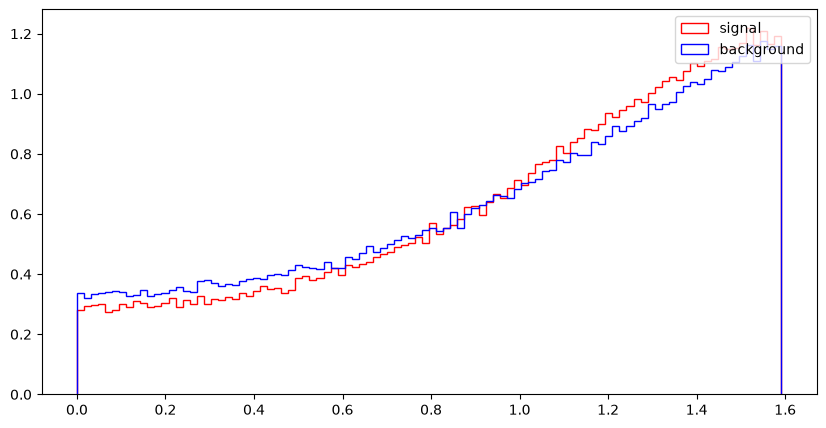

cos_theta_r1


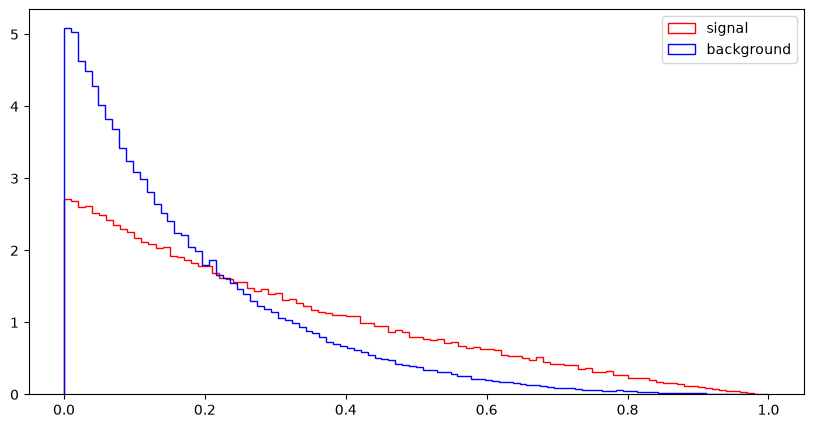

In [11]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

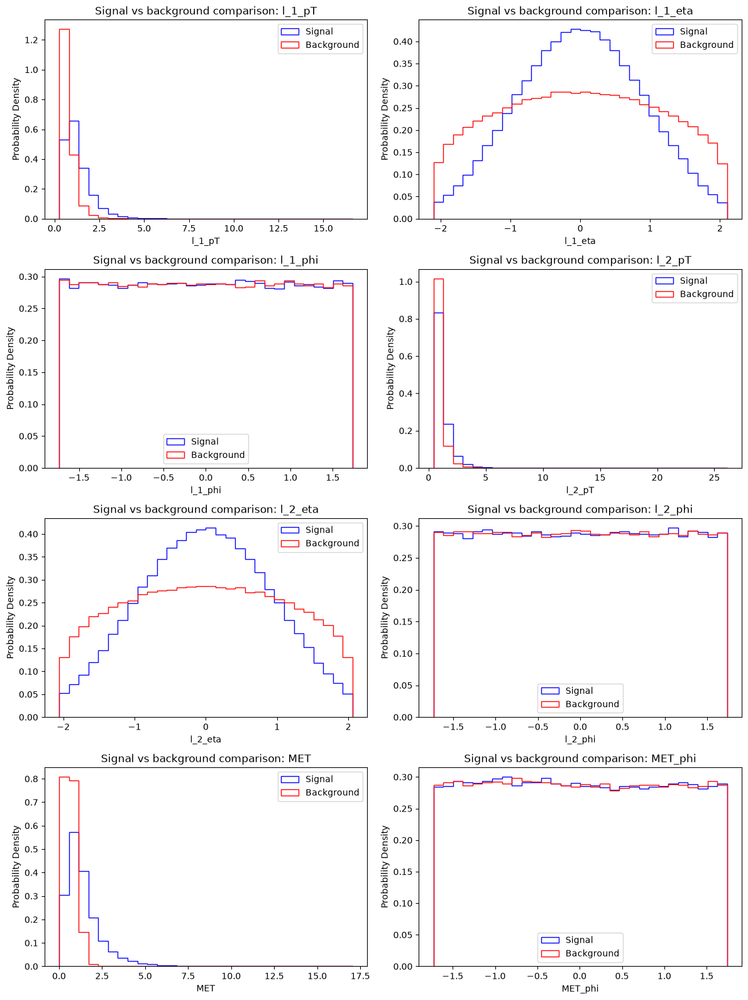

In [12]:
#for low-level features, RawNames
fig, ax = plt.subplots(4, 2, figsize = (12, 16))
ax = ax.flatten() #use to convert 2 D grid of plotting into 1D; easier to select ax, just by e.g. ax[0] instead of ax[0, 0]
for i, name in enumerate(RawNames):
    edges = np.linspace(df[name].min(), df[name].max(), 31)
    ax[i].hist(df_sig[name], bins = edges, color = 'blue', histtype = 'step', density = True, label = 'Signal')
    ax[i].hist(df_bkg[name], bins = edges, color = 'red', histtype = 'step', density = True, label = 'Background')

    ax[i].set_xlabel(name)
    ax[i].set_ylabel("Probability Density")
    ax[i].set_title(f"Signal vs background comparison: {name}")

    ax[i].legend(loc = 'best')

plt.tight_layout()
plt.show()
    
               
  
    
    

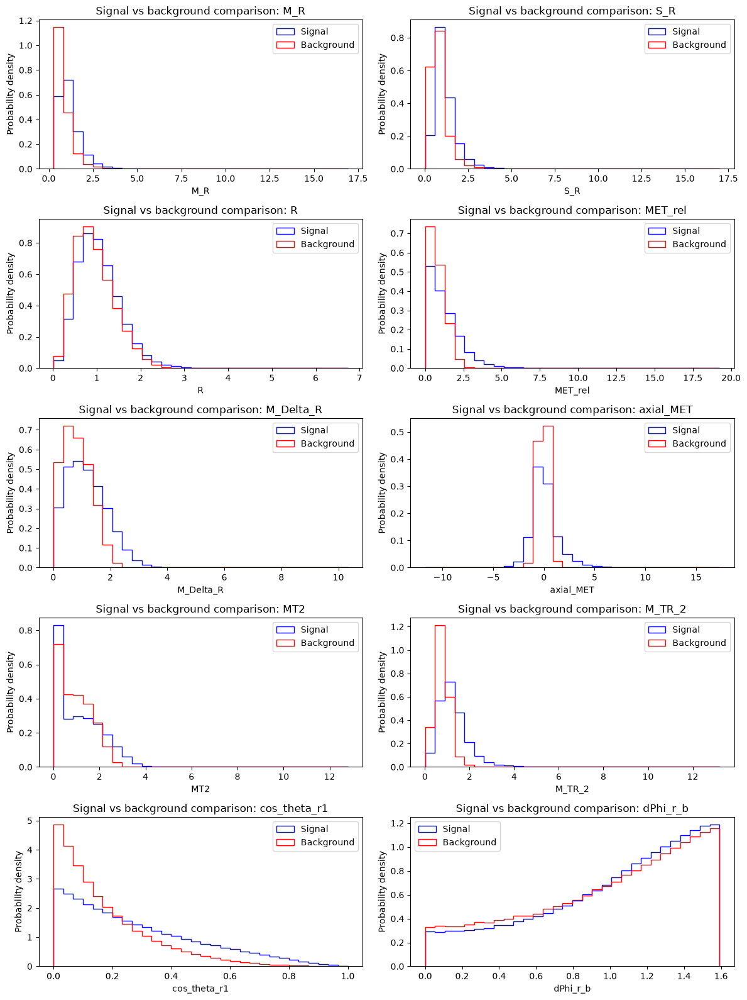

In [13]:
#for high level features, FeatureNames
fig, ax = plt.subplots(5, 2, figsize = (12, 16))
ax = ax.flatten() # 2D to 3D for accesing the axis

for i, var in enumerate(FeatureNames):
    edges = np.linspace(df[var].min(), df[var].max(), 31) #with 30 bins
    ax[i].hist(df_sig[var], bins = edges, color = 'blue', histtype = 'step', density = True, label = 'Signal')
    ax[i].hist(df_bkg[var], bins = edges, color = 'red', histtype = 'step', density = True, label = 'Background')

    ax[i].legend(loc = 'best')

    ax[i].set_xlabel(var)
    ax[i].set_ylabel('Probability density')
    ax[i].set_title(f"Signal vs background comparison: {var}")
    

plt.tight_layout()
plt.show()

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.


#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

In [15]:
#Part a
def make_pair_plot(data, columns, label_column = 'signal', bins = 30):
    signal = data[data[label_column] == 1]
    background = data[data[label_column] == 0]

    n = len(columns)

    fig, ax = plt.subplots(n, n, figsize = (4 * n, 5 * n), squeeze = False)

    for i, y_name in enumerate(columns):
        for j, x_name in enumerate(columns):
            if i == j:
                edges = np.linspace(data[y_name].min(), data[y_name].max(), bins + 1)
                
                ax[i,j].hist(signal[y_name],bins = edges, density = True, histtype = 'step', color = 'blue', label = 'Signal')
                ax[i,j].hist(background[y_name],bins = edges, density = True, histtype = 'step', color = 'red', label = 'Background')
                ax[i,j].set_ylabel("Probability Density")
            else:
                ax[i,j].scatter(signal[x_name], signal[y_name], color = 'blue', s = 4, alpha = 0.2, label = 'Signal')
                ax[i,j].scatter(background[x_name], background[y_name], color = 'red', s = 4, alpha = 0.2, label = 'Background')

                ax[i,j].set_ylabel(y_name)

            ax[i,j].set_xlabel(x_name)

    ax[0,0].legend()
    fig.tight_layout()
    plt.show()



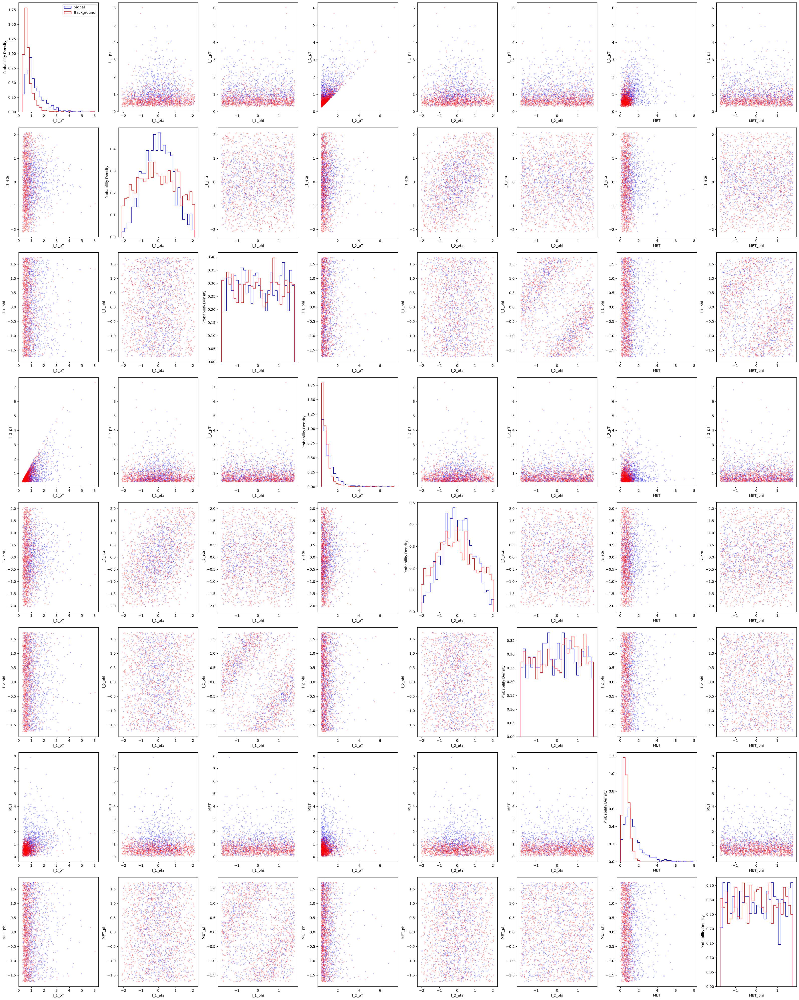

In [16]:
practice_data = df.sample(n=2000, random_state=42)

make_pair_plot(practice_data, RawNames)

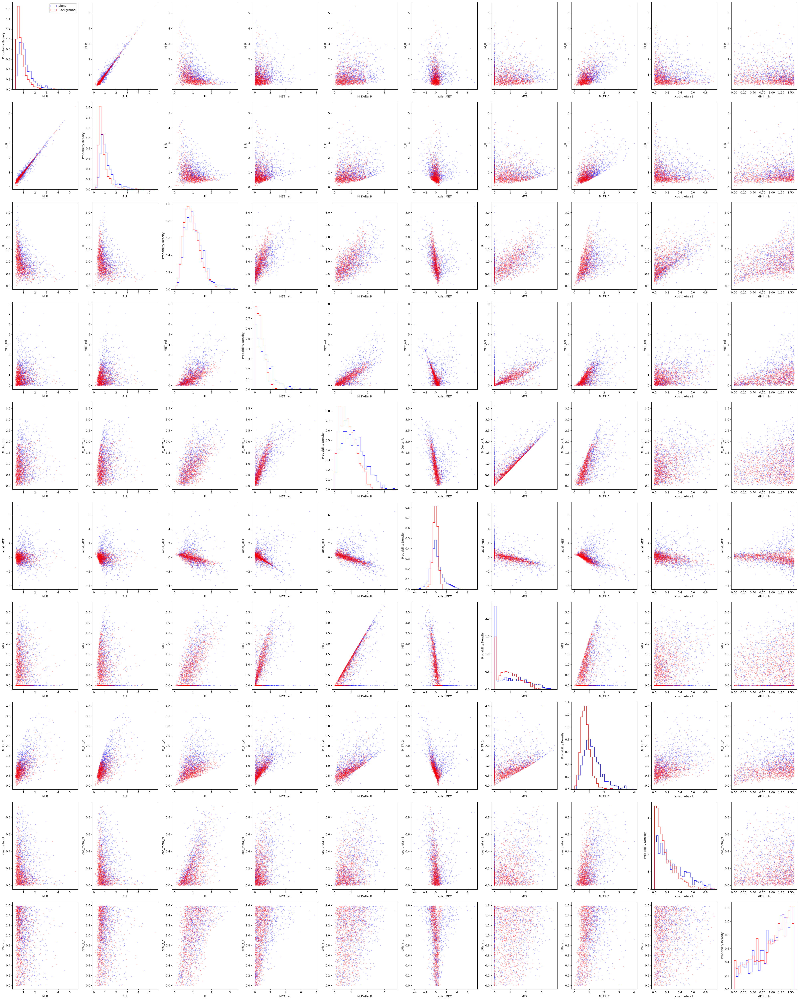

In [17]:
make_pair_plot(practice_data, FeatureNames)

In [18]:
#Part b making the function to be faster for plotting a pair plot
#For this I can do the sampling inside the function itself rather than outside the function.bot
def make_pair_plot(data, columns, label_column = 'signal', bins = 30, max_points = None):
    #Here, i added a condition which checks if our rows is higher than the max_points, if higher, it will
    # do a random sampling of data, random_state = 42 helps to choose the same rows again and again for each samples
    if max_points is not None and len(data) > max_points:
        data = data.sample(n = max_points, random_state = 42)
        
    signal = data[data[label_column] == 1]
    background = data[data[label_column] == 0]
    
    n = len(columns)

    fig, ax = plt.subplots(n, n, figsize = (4 * n, 5 * n), squeeze = False)

    for i, y_name in enumerate(columns):
        for j, x_name in enumerate(columns):
            if i == j:
                edges = np.linspace(data[y_name].min(), data[y_name].max(), bins + 1)
                
                ax[i,j].hist(signal[y_name],bins = edges, density = True, histtype = 'step', color = 'blue', label = 'Signal')
                ax[i,j].hist(background[y_name],bins = edges, density = True, histtype = 'step', color = 'red', label = 'Background')
                ax[i,j].set_ylabel("Probability Density")
            else:
                ax[i,j].scatter(signal[x_name], signal[y_name], color = 'blue', s = 4, alpha = 0.2, label = 'Signal')
                ax[i,j].scatter(background[x_name], background[y_name], color = 'red', s = 4, alpha = 0.2, label = 'Background')

                ax[i,j].set_ylabel(y_name)

            ax[i,j].set_xlabel(x_name)

    ax[0,0].legend()
    fig.tight_layout()
    plt.show()

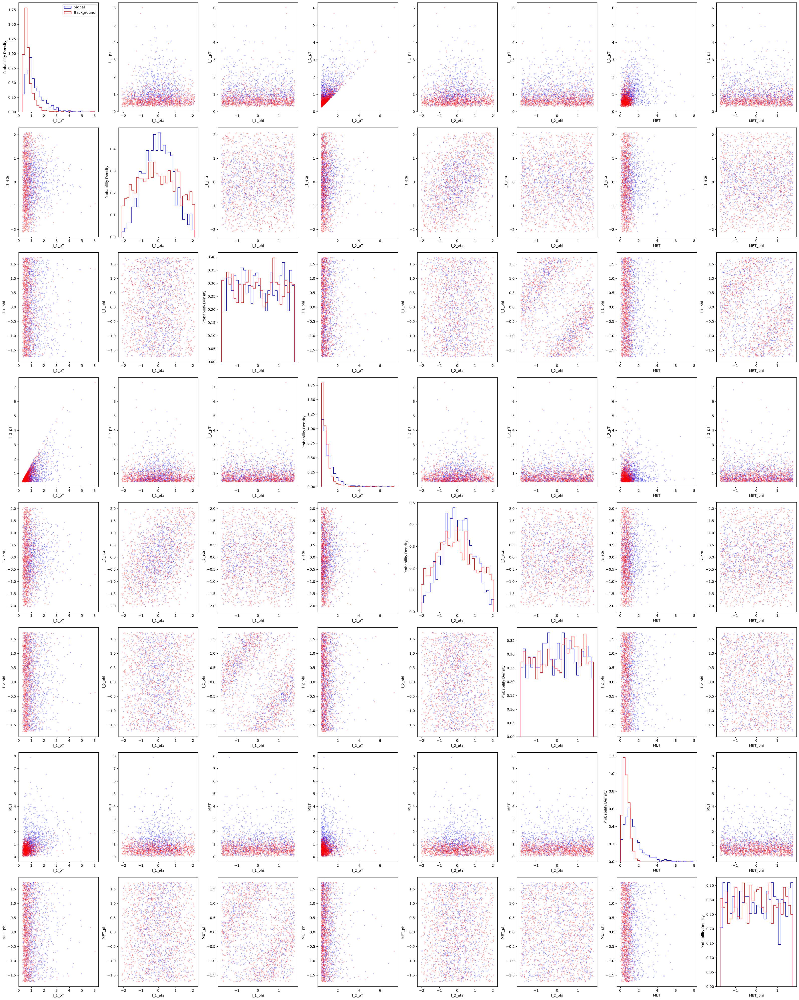

In [19]:
make_pair_plot(df, RawNames, max_points = 2000)

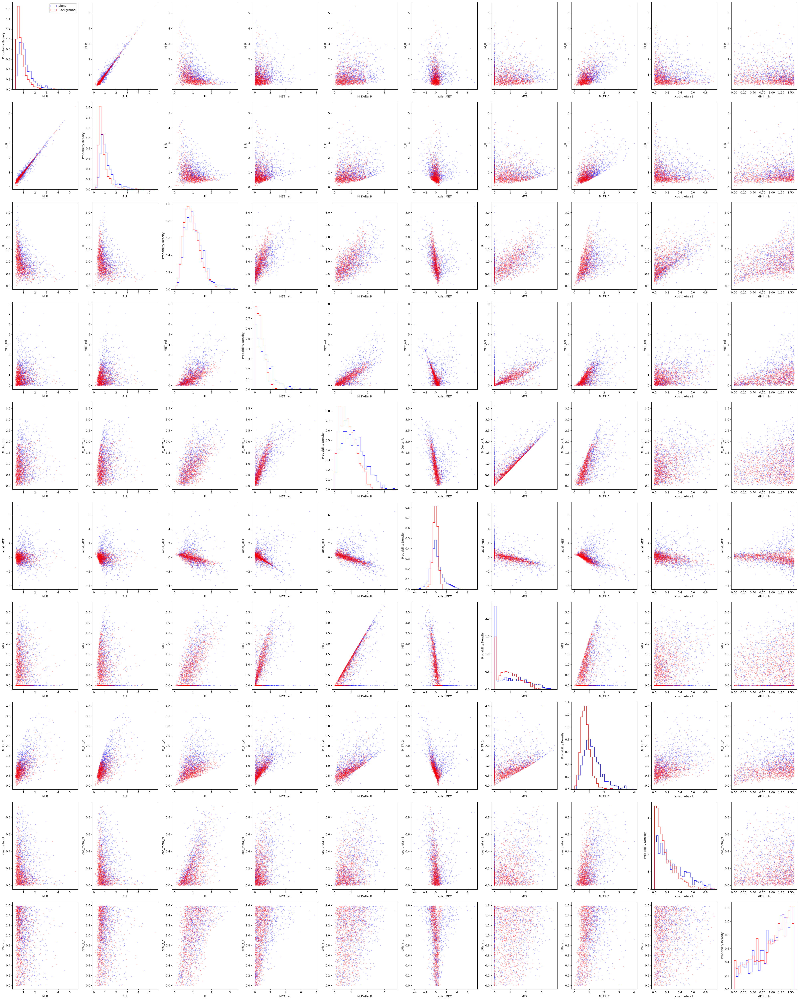

In [20]:
make_pair_plot(df, FeatureNames, max_points=2000)

## Part C   
Among the raw features, MET shows useful separation because signal tends toward larger values while background concentrates at smaller values. The lepton transverse momenta also show differences, and the eta distributions show signal more concentrated near zero. The phi distributions overlap strongly and appear less useful individually.

Among the engineered features, M_TR_2, MET_rel, M_Delta_R, and S_R show visible differences between signal and background. The later ROC results support MET and M_TR_2 as useful candidates, with AUCs of approximately 0.769 and 0.756. However, the distributions still overlap, so none of these features perfectly separates the two groups.

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [21]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

X,Y,Z
A,1,2
C,3,4
D,5,6


In [44]:
#Part b
import numpy as np
#calculating covariance and correlation matrix for all observables
cov_all = np.cov(df[VarNames[1:]], rowvar = False)
print(f"covariance of all obbservables: \n{cov_all}")

corr_all = np.corrcoef(df[VarNames[1:]], rowvar = False)
print(f"\ncorrelation of all observables: \n{corr_all}")

#calculating covariance and correlation matrix for low-level features
cov_low = np.cov(df[RawNames], rowvar = False)
print(f"\ncovariance of all low-level features: \n{cov_low}")

corr_low = np.corrcoef(df[RawNames], rowvar = False)
print(f"\ncorrelation of all low-level features : \n{corr_low}")

#calculating covariance and correlation matrix for high-level features
cov_high = np.cov(df[FeatureNames], rowvar = False)
print(f"\ncovariance of high-level features: \n{cov_high}")

corr_high = np.corrcoef(df[FeatureNames], rowvar = False)
print(f"\ncorrelation of high-level features: \n{corr_high}")


covariance of all obbservables: 
[[ 4.67481925e-01 -3.96674207e-04  7.66214265e-05  3.05037988e-01
  -3.48826988e-04  7.37336647e-04  2.28434336e-01 -9.36714374e-04
   9.75240349e-02 -9.73253567e-03  3.64432455e-01  2.87223483e-01
  -5.97024601e-02 -1.23988205e-02  3.42587023e-01  9.77389248e-02
  -4.69491360e-02  2.21632465e-02]
 [-3.96674207e-04  1.00430144e+00 -8.57630732e-04 -1.62905654e-04
   4.08312894e-01 -1.04201049e-03 -2.14697798e-03 -5.88968323e-04
  -1.37057212e-03 -1.10889241e-03 -5.53826632e-04 -6.68920291e-04
   3.01299870e-04  4.27122683e-04 -6.04009571e-04 -9.87471350e-04
  -7.40330277e-04  3.21632240e-04]
 [ 7.66214265e-05 -8.57630732e-04  1.00397336e+00  1.31296001e-03
   2.50714928e-04 -2.66810178e-01  7.66365893e-04 -1.84803977e-01
   7.06206018e-04 -1.87269105e-03  1.06306621e-03  8.68782730e-04
   2.01595554e-04  1.06029189e-03  1.46376567e-03  9.01233064e-04
   9.94305740e-04  2.59098396e-04]
 [ 3.05037988e-01 -1.62905654e-04  1.31296001e-03  4.25490163e-01
  -5

In [45]:
#Part c
from tabulate import tabulate
from IPython.display import HTML, display

# for all observables
print("Covariance of all observables")

table = tabulate(
    cov_all,
    headers = VarNames[1:],
    showindex = VarNames[1:],
    tablefmt = "html",
    floatfmt = ".3g"
)
display(HTML(table))

print()

print("Correlation of all observables")

table = tabulate(
    corr_all,
    headers = VarNames[1:],
    showindex = VarNames[1:],
    tablefmt = "html",
    floatfmt = ".3g"
)
display(HTML(table))

print()

# for all low-level features
print("Covariance of all low-level features")

table = tabulate(
    cov_low,
    headers = RawNames,
    showindex = RawNames,
    tablefmt = "html",
    floatfmt = ".3g"
)
display(HTML(table))

print()

print("Correlation of all low-level features")

table = tabulate(
    corr_low,
    headers = RawNames,
    showindex = RawNames,
    tablefmt = "html",
    floatfmt = ".3g"
)
display(HTML(table))

print()

# for high-level features
print("Covariance of high-level features")

table = tabulate(
    cov_high,
    headers = FeatureNames,
    showindex = FeatureNames,
    tablefmt = "html",
    floatfmt = ".3g"
)
display(HTML(table))

print()

print("Correlation of high-level features")

table = tabulate(
    corr_high,
    headers = FeatureNames,
    showindex = FeatureNames,
    tablefmt = "html",
    floatfmt = ".3g"
)
display(HTML(table))

Covariance of all observables


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937,0.0975,-0.00973,0.364,0.287,-0.0597,-0.0124,0.343,0.0977,-0.0469,0.0222
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589,-0.00137,-0.00111,-0.000554,-0.000669,0.000301,0.000427,-0.000604,-0.000987,-0.00074,0.000322
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185,0.000706,-0.00187,0.00106,0.000869,0.000202,0.00106,0.00146,0.000901,0.000994,0.000259
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156,-0.000534,0.0513,0.325,0.163,-0.0994,-0.0689,0.322,0.00572,-0.00383,-0.0279
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322,0.00108,-0.000756,-0.000608,1.89e-05,0.000321,0.0014,-0.000679,0.00067,-0.000307,0.000296
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354,0.00145,-0.0018,0.00076,0.000509,0.000551,0.00226,0.000906,0.00133,-0.000241,3.7e-05
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.0731
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1,-0.0049,-0.000442,-0.00148,-0.0012,-0.00023,8.39e-05,-0.00171,-0.00057,-0.00171,0.000119
MET_rel,0.0975,-0.00137,0.000706,-0.000534,0.00108,0.00145,0.546,-0.0049,0.79,-0.12,0.0437,0.302,0.249,0.409,0.0823,0.415,0.146,0.0553
axial_MET,-0.00973,-0.00111,-0.00187,0.0513,-0.000756,-0.0018,0.154,-0.000442,-0.12,1.01,0.0171,-0.185,-0.181,-0.461,-0.0414,-0.233,-0.0251,-0.0537



Correlation of all observables


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.000579,0.000112,0.684,-0.000509,0.00108,0.383,-0.00137,0.16,-0.0142,0.851,0.723,-0.186,-0.0211,0.811,0.229,-0.157,0.165
l_1_eta,-0.000579,1,-0.000854,-0.000249,0.406,-0.00104,-0.00245,-0.000587,-0.00154,-0.0011,-0.000882,-0.00115,0.000639,0.000496,-0.000975,-0.00158,-0.00169,0.00163
l_1_phi,0.000112,-0.000854,1,0.00201,0.000249,-0.266,0.000876,-0.184,0.000793,-0.00186,0.00169,0.00149,0.000427,0.00123,0.00236,0.00144,0.00228,0.00131
l_2_pT,0.684,-0.000249,0.00201,1,-0.00088,0.000239,0.14,-0.00239,-0.000921,0.0785,0.797,0.43,-0.324,-0.123,0.799,0.0141,-0.0135,-0.217
l_2_eta,-0.000509,0.406,0.000249,-0.00088,1,0.000439,0.000436,-0.000321,0.00122,-0.000752,-0.000967,3.24e-05,0.000679,0.00162,-0.00109,0.00107,-0.000701,0.0015
l_2_phi,0.00108,-0.00104,-0.266,0.000239,0.000439,1,-0.000348,-0.0353,0.00162,-0.00179,0.00121,0.000874,0.00117,0.00263,0.00146,0.00212,-0.000552,0.000188
MET,0.383,-0.00245,0.000876,0.14,0.000436,-0.000348,1,-0.00319,0.704,0.176,0.264,0.72,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.00137,-0.000587,-0.184,-0.00239,-0.000321,-0.0353,-0.00319,1,-0.0055,-0.00044,-0.00236,-0.00206,-0.000487,9.75e-05,-0.00276,-0.000913,-0.00391,0.000605
MET_rel,0.16,-0.00154,0.000793,-0.000921,0.00122,0.00162,0.704,-0.0055,1,-0.134,0.0785,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.0142,-0.0011,-0.00186,0.0785,-0.000752,-0.00179,0.176,-0.00044,-0.134,1,0.0273,-0.317,-0.383,-0.535,-0.0668,-0.373,-0.0574,-0.272



Covariance of all low-level features


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1



Correlation of all low-level features


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.000579,0.000112,0.684,-0.000509,0.00108,0.383,-0.00137
l_1_eta,-0.000579,1,-0.000854,-0.000249,0.406,-0.00104,-0.00245,-0.000587
l_1_phi,0.000112,-0.000854,1,0.00201,0.000249,-0.266,0.000876,-0.184
l_2_pT,0.684,-0.000249,0.00201,1,-0.00088,0.000239,0.14,-0.00239
l_2_eta,-0.000509,0.406,0.000249,-0.00088,1,0.000439,0.000436,-0.000321
l_2_phi,0.00108,-0.00104,-0.266,0.000239,0.000439,1,-0.000348,-0.0353
MET,0.383,-0.00245,0.000876,0.14,0.000436,-0.000348,1,-0.00319
MET_phi,-0.00137,-0.000587,-0.184,-0.00239,-0.000321,-0.0353,-0.00319,1



Covariance of high-level features


,M_R,S_R,R,MET_rel,M_Delta_R,axial_MET,MT2,M_TR_2,cos_theta_r1,dPhi_r_b
M_R,0.392,0.38,-0.113,0.0437,0.0739,0.0171,-0.0365,0.21,-0.0143,-0.029
S_R,0.38,0.382,-0.0834,0.0823,0.0958,-0.0414,-0.011,0.228,-0.0104,-0.00346
R,-0.113,-0.0834,0.222,0.249,0.165,-0.181,0.232,0.104,0.0582,0.0871
MET_rel,0.0437,0.0823,0.249,0.79,0.415,-0.12,0.409,0.302,0.0553,0.146
M_Delta_R,0.0739,0.0958,0.165,0.415,0.389,-0.233,0.433,0.242,0.0392,0.0422
axial_MET,0.0171,-0.0414,-0.181,-0.12,-0.233,1.01,-0.461,-0.185,-0.0537,-0.0251
MT2,-0.0365,-0.011,0.232,0.409,0.433,-0.461,0.738,0.189,0.0446,0.0209
M_TR_2,0.21,0.228,0.104,0.302,0.242,-0.185,0.189,0.338,0.0517,0.0581
cos_theta_r1,-0.0143,-0.0104,0.0582,0.0553,0.0392,-0.0537,0.0446,0.0517,0.0388,0.00908
dPhi_r_b,-0.029,-0.00346,0.0871,0.146,0.0422,-0.0251,0.0209,0.0581,0.00908,0.19



Correlation of high-level features


,M_R,S_R,R,MET_rel,M_Delta_R,axial_MET,MT2,M_TR_2,cos_theta_r1,dPhi_r_b
M_R,1,0.981,-0.383,0.0785,0.189,0.0273,-0.0679,0.577,-0.116,-0.106
S_R,0.981,1,-0.287,0.15,0.249,-0.0668,-0.0208,0.635,-0.0851,-0.0128
R,-0.383,-0.287,1,0.595,0.564,-0.383,0.574,0.38,0.627,0.424
MET_rel,0.0785,0.15,0.595,1,0.748,-0.134,0.535,0.584,0.316,0.378
M_Delta_R,0.189,0.249,0.564,0.748,1,-0.373,0.809,0.668,0.319,0.155
axial_MET,0.0273,-0.0668,-0.383,-0.134,-0.373,1,-0.535,-0.317,-0.272,-0.0574
MT2,-0.0679,-0.0208,0.574,0.535,0.809,-0.535,1,0.379,0.264,0.0558
M_TR_2,0.577,0.635,0.38,0.584,0.668,-0.317,0.379,1,0.451,0.229
cos_theta_r1,-0.116,-0.0851,0.627,0.316,0.319,-0.272,0.264,0.451,1,0.106
dPhi_r_b,-0.106,-0.0128,0.424,0.378,0.155,-0.0574,0.0558,0.229,0.106,1


In [91]:
#Part d
def show_relationships(data, columns, title):
    values = data[columns]

    #calculating the covariance and correlation matrices
    covariance = np.cov(values, rowvar = False)
    correlation = np.corrcoef(values, rowvar = False)

    #Displaying the covariance title and its table
    print("Covariance of:",title)
    table = tabulate(
        covariance,
        headers = columns,
        showindex = columns,
        tablefmt = "html",
        floatfmt = ".3g"
        
    )
    display(HTML(table))

    #Displaying the correlation title and its table
    print("\nCorrelation of:",title)
    table = tabulate(
        correlation,
        headers = columns,
        showindex = columns,
        tablefmt = "html",
        floatfmt = ".3g"
        
    )
    display(HTML(table))

In [49]:
#testing the function 
show_relationships(df, VarNames[1:], "All features")
show_relationships(df, RawNames, "Low-Level features")
show_relationships(df, FeatureNames, "High-Level features")

Covariance of: All features


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937,0.0975,-0.00973,0.364,0.287,-0.0597,-0.0124,0.343,0.0977,-0.0469,0.0222
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589,-0.00137,-0.00111,-0.000554,-0.000669,0.000301,0.000427,-0.000604,-0.000987,-0.00074,0.000322
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185,0.000706,-0.00187,0.00106,0.000869,0.000202,0.00106,0.00146,0.000901,0.000994,0.000259
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156,-0.000534,0.0513,0.325,0.163,-0.0994,-0.0689,0.322,0.00572,-0.00383,-0.0279
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322,0.00108,-0.000756,-0.000608,1.89e-05,0.000321,0.0014,-0.000679,0.00067,-0.000307,0.000296
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354,0.00145,-0.0018,0.00076,0.000509,0.000551,0.00226,0.000906,0.00133,-0.000241,3.7e-05
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.0731
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1,-0.0049,-0.000442,-0.00148,-0.0012,-0.00023,8.39e-05,-0.00171,-0.00057,-0.00171,0.000119
MET_rel,0.0975,-0.00137,0.000706,-0.000534,0.00108,0.00145,0.546,-0.0049,0.79,-0.12,0.0437,0.302,0.249,0.409,0.0823,0.415,0.146,0.0553
axial_MET,-0.00973,-0.00111,-0.00187,0.0513,-0.000756,-0.0018,0.154,-0.000442,-0.12,1.01,0.0171,-0.185,-0.181,-0.461,-0.0414,-0.233,-0.0251,-0.0537



Correlation of: All features


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.000579,0.000112,0.684,-0.000509,0.00108,0.383,-0.00137,0.16,-0.0142,0.851,0.723,-0.186,-0.0211,0.811,0.229,-0.157,0.165
l_1_eta,-0.000579,1,-0.000854,-0.000249,0.406,-0.00104,-0.00245,-0.000587,-0.00154,-0.0011,-0.000882,-0.00115,0.000639,0.000496,-0.000975,-0.00158,-0.00169,0.00163
l_1_phi,0.000112,-0.000854,1,0.00201,0.000249,-0.266,0.000876,-0.184,0.000793,-0.00186,0.00169,0.00149,0.000427,0.00123,0.00236,0.00144,0.00228,0.00131
l_2_pT,0.684,-0.000249,0.00201,1,-0.00088,0.000239,0.14,-0.00239,-0.000921,0.0785,0.797,0.43,-0.324,-0.123,0.799,0.0141,-0.0135,-0.217
l_2_eta,-0.000509,0.406,0.000249,-0.00088,1,0.000439,0.000436,-0.000321,0.00122,-0.000752,-0.000967,3.24e-05,0.000679,0.00162,-0.00109,0.00107,-0.000701,0.0015
l_2_phi,0.00108,-0.00104,-0.266,0.000239,0.000439,1,-0.000348,-0.0353,0.00162,-0.00179,0.00121,0.000874,0.00117,0.00263,0.00146,0.00212,-0.000552,0.000188
MET,0.383,-0.00245,0.000876,0.14,0.000436,-0.000348,1,-0.00319,0.704,0.176,0.264,0.72,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.00137,-0.000587,-0.184,-0.00239,-0.000321,-0.0353,-0.00319,1,-0.0055,-0.00044,-0.00236,-0.00206,-0.000487,9.75e-05,-0.00276,-0.000913,-0.00391,0.000605
MET_rel,0.16,-0.00154,0.000793,-0.000921,0.00122,0.00162,0.704,-0.0055,1,-0.134,0.0785,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.0142,-0.0011,-0.00186,0.0785,-0.000752,-0.00179,0.176,-0.00044,-0.134,1,0.0273,-0.317,-0.383,-0.535,-0.0668,-0.373,-0.0574,-0.272


Covariance of: Low-Level features


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1



Correlation of: Low-Level features


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.000579,0.000112,0.684,-0.000509,0.00108,0.383,-0.00137
l_1_eta,-0.000579,1,-0.000854,-0.000249,0.406,-0.00104,-0.00245,-0.000587
l_1_phi,0.000112,-0.000854,1,0.00201,0.000249,-0.266,0.000876,-0.184
l_2_pT,0.684,-0.000249,0.00201,1,-0.00088,0.000239,0.14,-0.00239
l_2_eta,-0.000509,0.406,0.000249,-0.00088,1,0.000439,0.000436,-0.000321
l_2_phi,0.00108,-0.00104,-0.266,0.000239,0.000439,1,-0.000348,-0.0353
MET,0.383,-0.00245,0.000876,0.14,0.000436,-0.000348,1,-0.00319
MET_phi,-0.00137,-0.000587,-0.184,-0.00239,-0.000321,-0.0353,-0.00319,1


Covariance of: High-Level features


,M_R,S_R,R,MET_rel,M_Delta_R,axial_MET,MT2,M_TR_2,cos_theta_r1,dPhi_r_b
M_R,0.392,0.38,-0.113,0.0437,0.0739,0.0171,-0.0365,0.21,-0.0143,-0.029
S_R,0.38,0.382,-0.0834,0.0823,0.0958,-0.0414,-0.011,0.228,-0.0104,-0.00346
R,-0.113,-0.0834,0.222,0.249,0.165,-0.181,0.232,0.104,0.0582,0.0871
MET_rel,0.0437,0.0823,0.249,0.79,0.415,-0.12,0.409,0.302,0.0553,0.146
M_Delta_R,0.0739,0.0958,0.165,0.415,0.389,-0.233,0.433,0.242,0.0392,0.0422
axial_MET,0.0171,-0.0414,-0.181,-0.12,-0.233,1.01,-0.461,-0.185,-0.0537,-0.0251
MT2,-0.0365,-0.011,0.232,0.409,0.433,-0.461,0.738,0.189,0.0446,0.0209
M_TR_2,0.21,0.228,0.104,0.302,0.242,-0.185,0.189,0.338,0.0517,0.0581
cos_theta_r1,-0.0143,-0.0104,0.0582,0.0553,0.0392,-0.0537,0.0446,0.0517,0.0388,0.00908
dPhi_r_b,-0.029,-0.00346,0.0871,0.146,0.0422,-0.0251,0.0209,0.0581,0.00908,0.19



Correlation of: High-Level features


,M_R,S_R,R,MET_rel,M_Delta_R,axial_MET,MT2,M_TR_2,cos_theta_r1,dPhi_r_b
M_R,1,0.981,-0.383,0.0785,0.189,0.0273,-0.0679,0.577,-0.116,-0.106
S_R,0.981,1,-0.287,0.15,0.249,-0.0668,-0.0208,0.635,-0.0851,-0.0128
R,-0.383,-0.287,1,0.595,0.564,-0.383,0.574,0.38,0.627,0.424
MET_rel,0.0785,0.15,0.595,1,0.748,-0.134,0.535,0.584,0.316,0.378
M_Delta_R,0.189,0.249,0.564,0.748,1,-0.373,0.809,0.668,0.319,0.155
axial_MET,0.0273,-0.0668,-0.383,-0.134,-0.373,1,-0.535,-0.317,-0.272,-0.0574
MT2,-0.0679,-0.0208,0.574,0.535,0.809,-0.535,1,0.379,0.264,0.0558
M_TR_2,0.577,0.635,0.38,0.584,0.668,-0.317,0.379,1,0.451,0.229
cos_theta_r1,-0.116,-0.0851,0.627,0.316,0.319,-0.272,0.264,0.451,1,0.106
dPhi_r_b,-0.106,-0.0128,0.424,0.378,0.155,-0.0574,0.0558,0.229,0.106,1


## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

### 5.1
#For low-level features

The following selections are based on visual inspection of the
signal (blue) and background (red) distributions.
The threshold $c$ will be determined in the following exercises.

### Low-level observables

| Observable | Proposed selection | Visual justification |
|---|---|---|
| `l_1_pT` | $x > c$ | Signal extends toward larger values than background. |
| `l_1_eta` | $\lvert x\rvert < c$ | Signal is more concentrated near zero. |
| `l_1_phi` | No clear useful cut | Both distributions are approximately flat and overlap. |
| `l_2_pT` | $x > c$ (tentative) | Signal appears shifted toward larger values. |
| `l_2_eta` | $\lvert x\rvert < c$ | Signal is more concentrated near zero. |
| `l_2_phi` | No clear useful cut | Signal and background overlap almost completely. |
| `MET` | $x > c$ | Signal has a more pronounced high-value tail. |
| `MET_phi` | No clear useful cut | Both distributions are approximately flat and overlap. |

### High-level observables

| Observable | Proposed selection | Visual justification |
|---|---|---|
| `M_R` | $x > c$ | Signal extends toward larger values. |
| `S_R` | $x > c$ | Signal is shifted toward higher values. |
| `R` | $x > c$ (tentative) | Signal appears slightly shifted upward, with strong overlap. |
| `MET_rel` | $x > c$ | Signal has a more pronounced high-value tail. |
| `M_Delta_R` | $x > c$ | Signal is relatively more common at larger values. |
| `axial_MET` | $x > c$ (tentative) | Signal has a more noticeable positive tail. |
| `MT2` | $\lvert x\rvert < c$ (tentative) | Signal has a narrow concentration near zero. |
| `M_TR_2` | $x > c$ | Signal is shifted toward larger values. |
| `cos_theta_r1` | $x > c$ | Background concentrates near zero; signal is relatively more common at higher values. |
| `dPhi_r_b` | No clear useful cut | The curves nearly coincide; an upper-value selection is only a weak candidate. |

### Interpretation

These are preliminary visual choices, not proven optimal cuts.
For selections around zero, the center is $\mu = 0$.
Efficiency and significance scans will determine suitable thresholds
and test whether these selections improve separation.

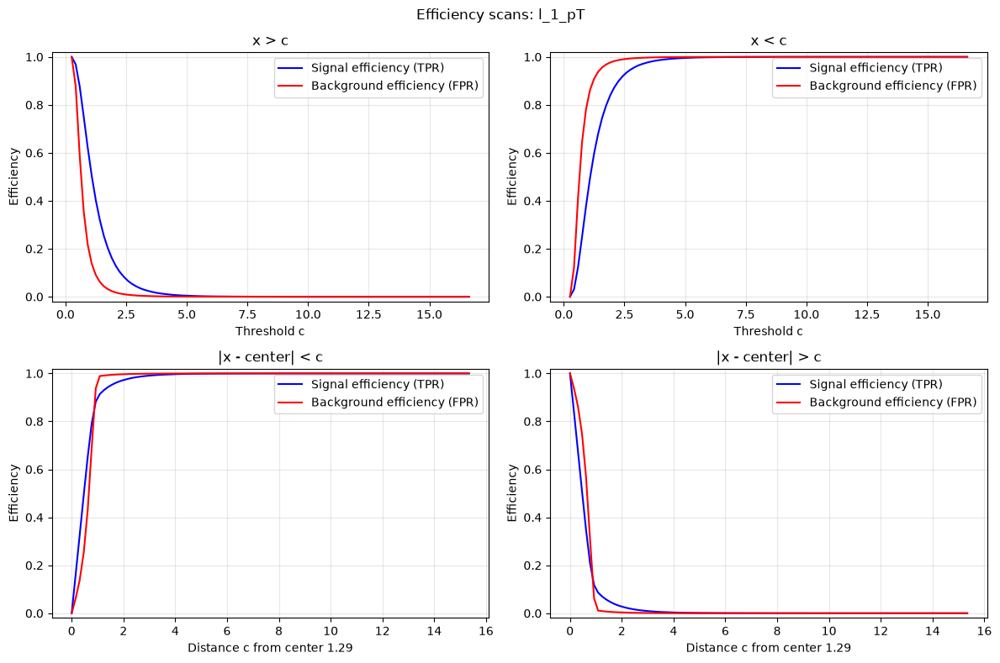

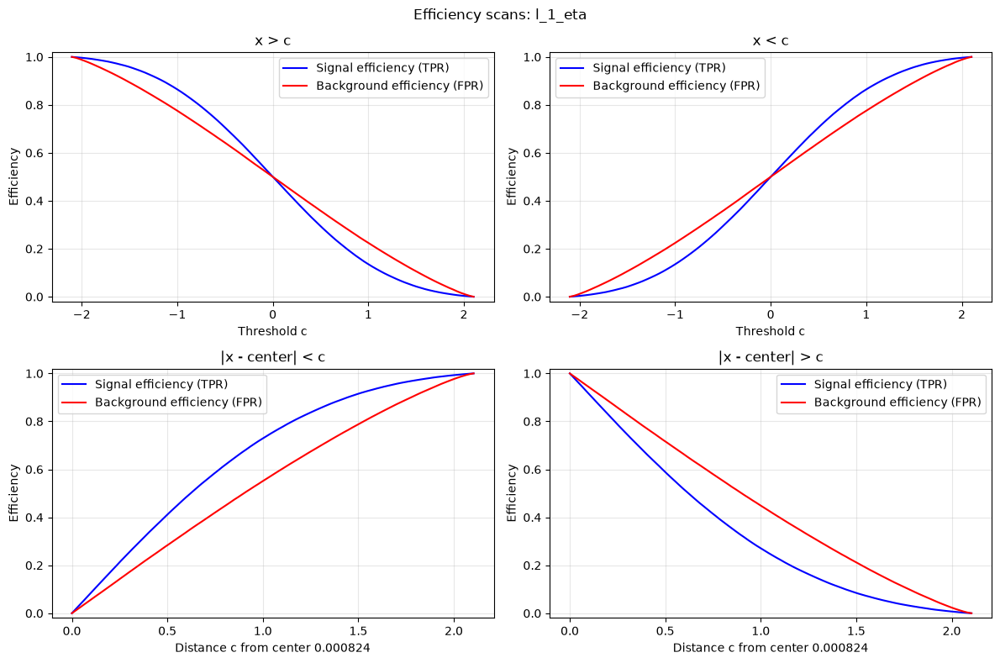

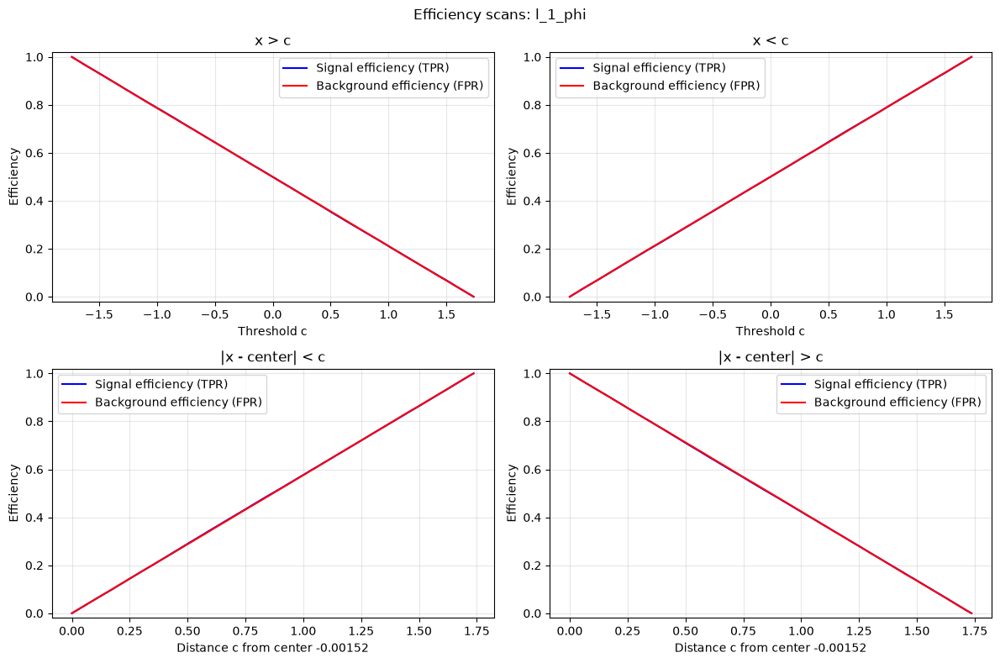

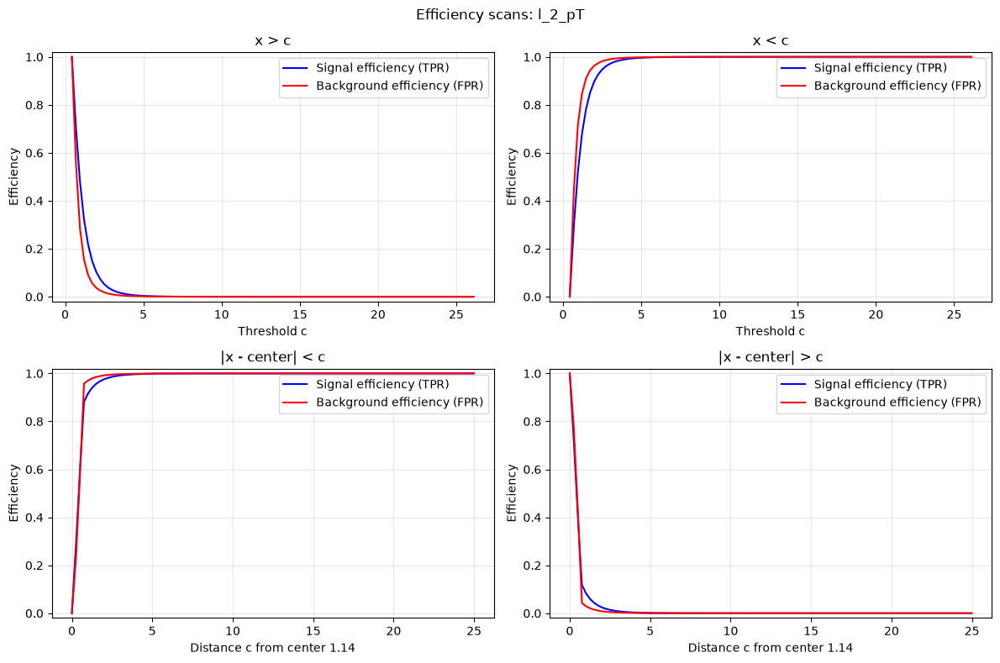

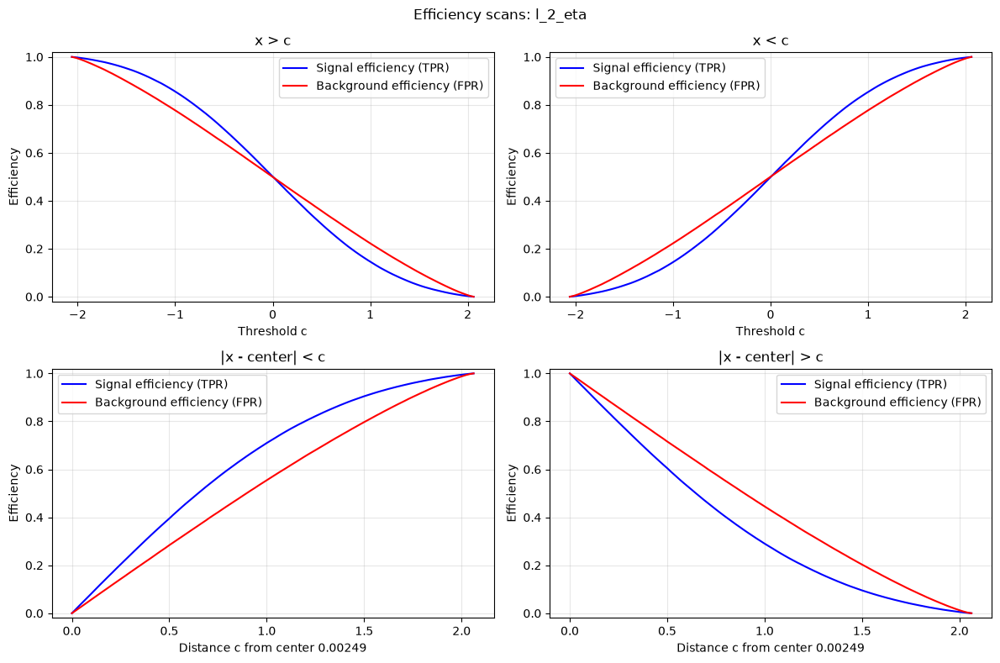

...

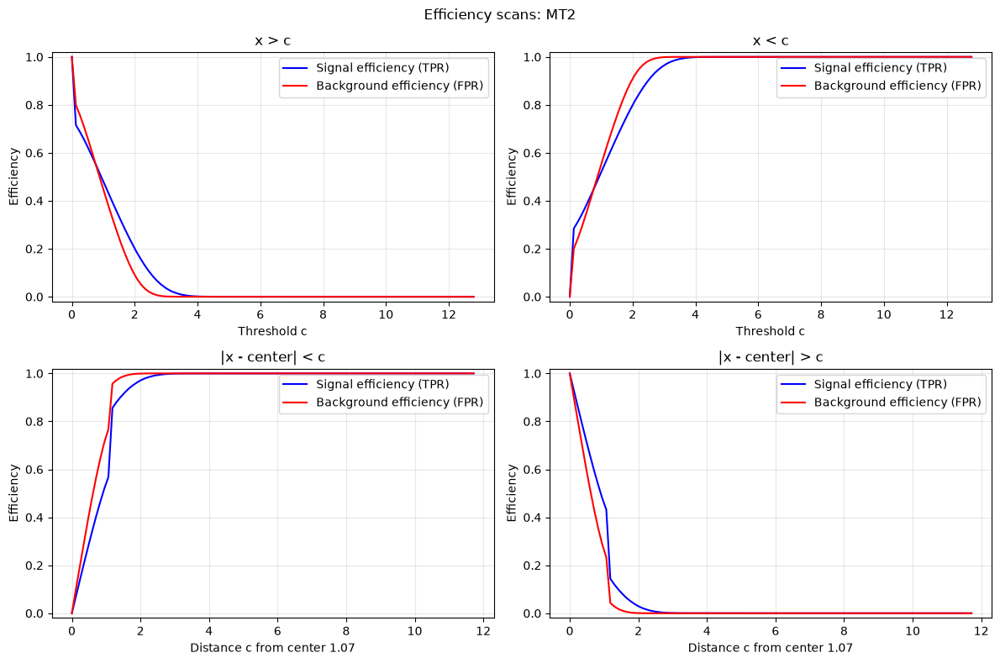

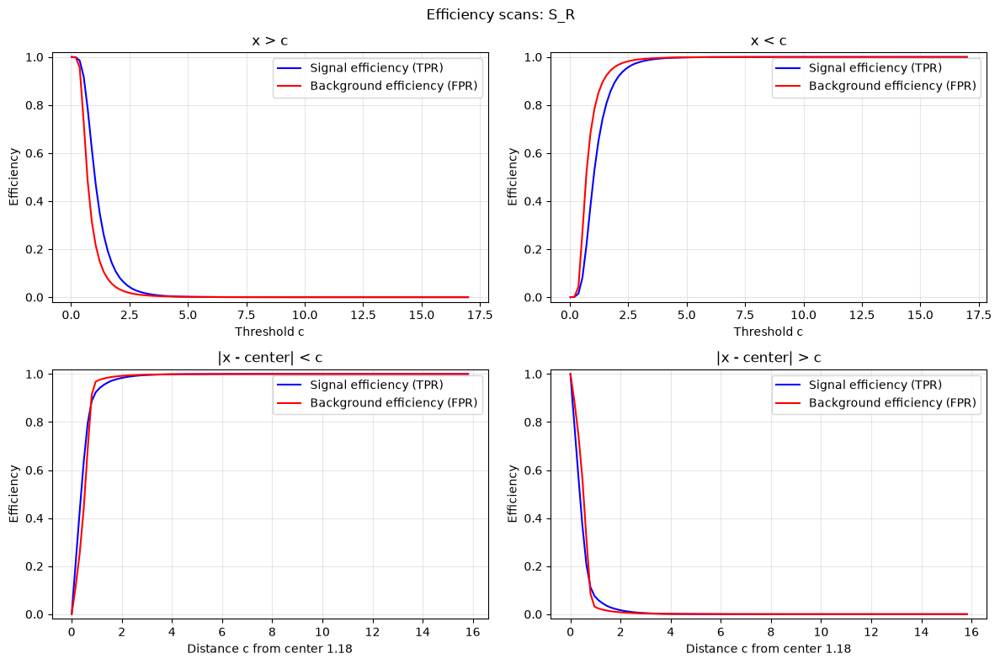

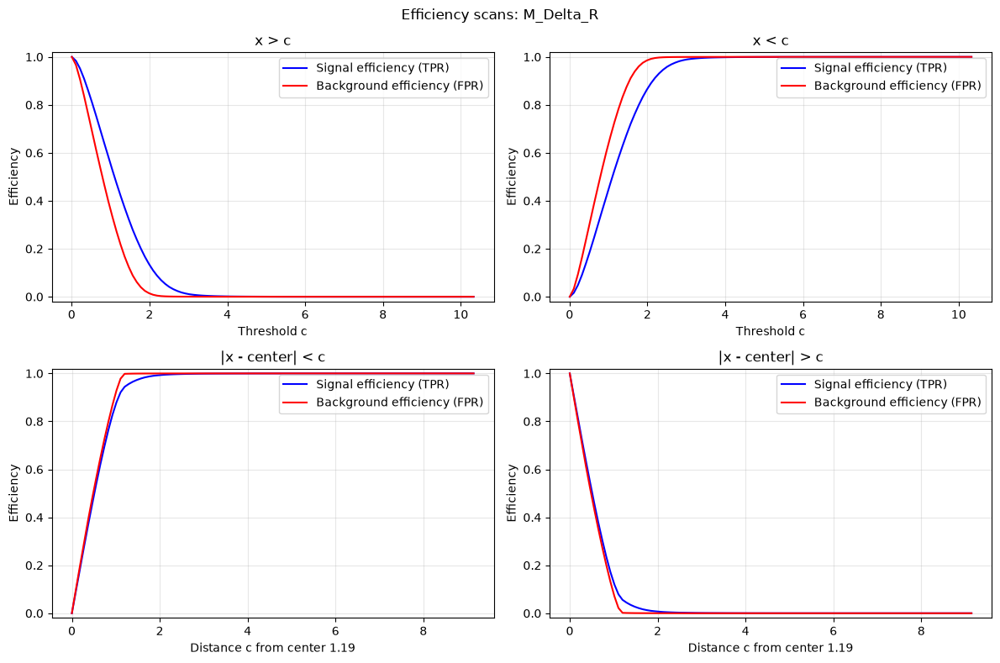

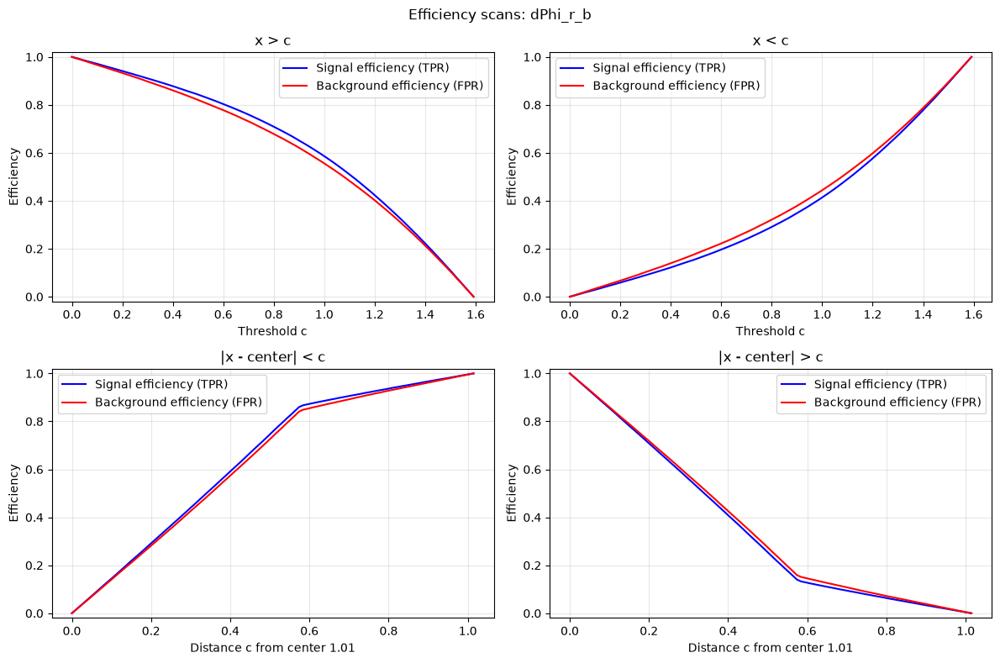

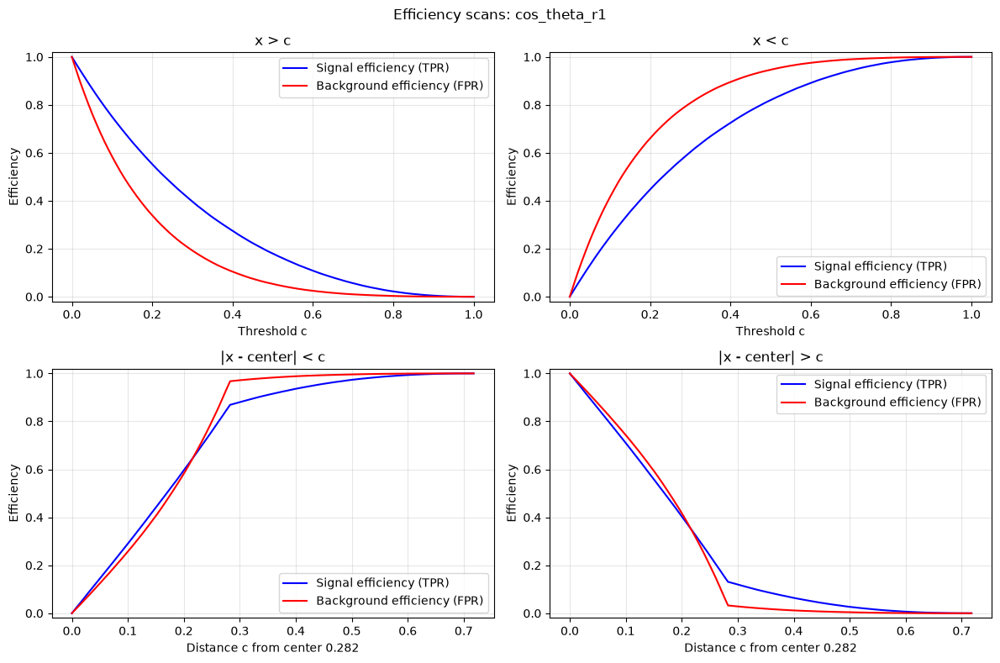

In [74]:
#5.2 

def scan_efficiencies(df_sig, df_bkg, feature, thresholds, direction = "above", center = 0):
    signal_efficiencies = []
    background_efficiencies = []
    
    for threshold in thresholds:
        #create a mask for each thresholds
        if direction == "above":
            signal_mask = df_sig[feature] > threshold
            background_mask = df_bkg[feature] > threshold
            
        elif direction == "below":
            signal_mask = df_sig[feature] < threshold
            background_mask = df_bkg[feature] < threshold
            
        elif direction == "inside":
            signal_mask = np.abs(df_sig[feature] - center) < threshold
            background_mask = np.abs(df_bkg[feature] - center) < threshold

        elif direction == "outside":
            signal_mask = np.abs(df_sig[feature] - center) > threshold
            background_mask = np.abs(df_bkg[feature] - center) > threshold

        else:
            raise ValueError("cut direction is unknown")
            
        #calculate a efficiency corresponding to each thresholds
        signal_efficiency = signal_mask.sum()/len(df_sig)
        background_efficiency = background_mask.sum()/len(df_bkg)
        
        #appends it efficiencies to corresponding classes
        signal_efficiencies.append(signal_efficiency)
        background_efficiencies.append(background_efficiency)

    return np.array(signal_efficiencies), np.array(background_efficiencies)

# Store each feature's scans for later exercises.
efficiency_results = {}

directions = ["above", "below", "inside", "outside"]

for feature in VarNames[1:]:

    center = df_sig[feature].mean()

    minimum = df[feature].min()
    maximum = df[feature].max()

    # Extend slightly beyond the observed range to include endpoints
    # where all or none of the observations pass.
    padding = max(maximum - minimum, 1.0) * 1e-6

    value_thresholds = np.linspace(
        minimum - padding,
        maximum + padding,
        100
    )

    # For inside/outside cuts, thresholds are distances from the center.
    max_distance = np.abs(df[feature] - center).max()

    distance_thresholds = np.linspace(
        0,
        max_distance + padding,
        100
    )

    efficiency_results[feature] = {}

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes = axes.flatten()

    for i, direction in enumerate(directions):

        if direction in ["above", "below"]:
            thresholds = value_thresholds
            xlabel = "Threshold c"
        else:
            thresholds = distance_thresholds
            xlabel = f"Distance c from center {center:.3g}"

        signal_efficiencies, background_efficiencies = scan_efficiencies(
            df_sig,
            df_bkg,
            feature,
            thresholds,
            direction=direction,
            center=center
        )

        efficiency_results[feature][direction] = {
            "thresholds": thresholds,
            "signal_efficiencies": signal_efficiencies,
            "background_efficiencies": background_efficiencies,
            "center": center
        }

        axes[i].plot(
            thresholds,
            signal_efficiencies,
            color="blue",
            label="Signal efficiency (TPR)"
        )

        axes[i].plot(
            thresholds,
            background_efficiencies,
            color="red",
            label="Background efficiency (FPR)"
        )

        conditions = {
            "above": "x > c",
            "below": "x < c",
            "inside": "|x - center| < c",
            "outside": "|x - center| > c"
        }

        axes[i].set_title(conditions[direction])
        axes[i].set_xlabel(xlabel)
        axes[i].set_ylabel("Efficiency")
        axes[i].set_ylim(-0.02, 1.02)
        axes[i].legend()
        axes[i].grid(alpha=0.3)

    fig.suptitle(f"Efficiency scans: {feature}")
    fig.tight_layout()
    plt.show()


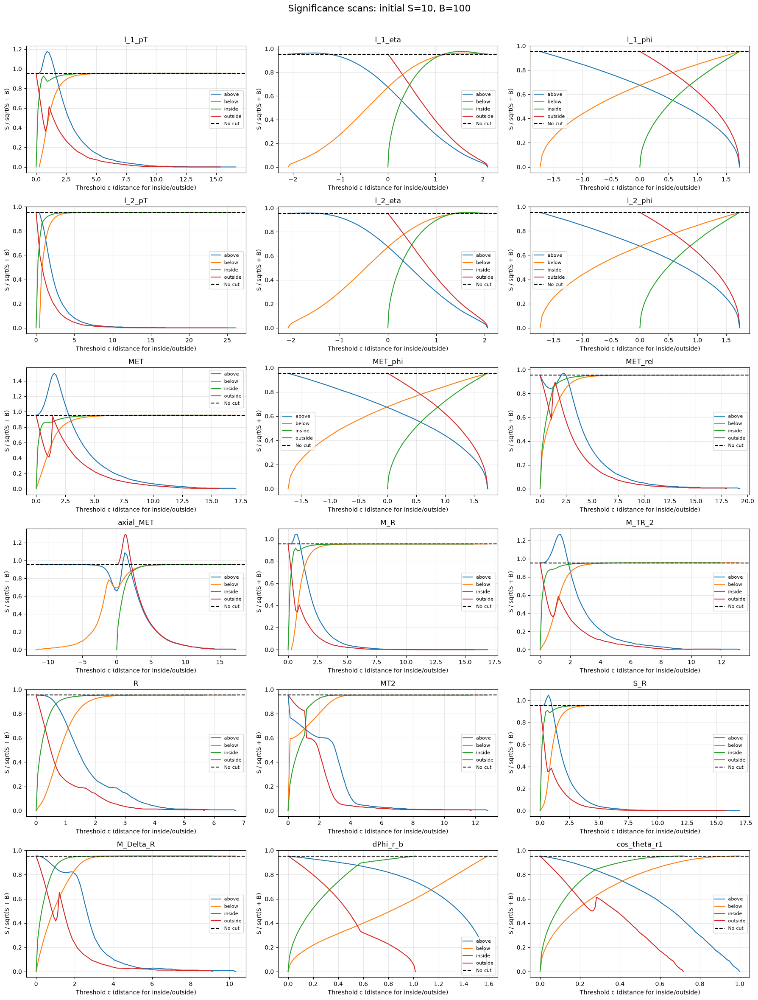

Initial signal: 10
Initial background: 100
No-cut significance: 0.9535


Feature,Best tested cut,Signal efficiency,Background efficiency,Expected S after,Expected B after,Significance
MET,x > 1.551,0.3215,0.01391,3.215,1.391,1.498
axial_MET,|x - (0.08931)| > 1.218,0.2674,0.01597,2.674,1.597,1.294
M_TR_2,x > 1.342,0.369,0.04781,3.69,4.781,1.268
l_1_pT,x > 0.9172,0.6215,0.2171,6.215,21.71,1.176
S_R,x > 0.7127,0.7841,0.4828,7.841,48.28,1.047
M_R,x > 0.6037,0.8721,0.6128,8.721,61.28,1.042
l_1_eta,|x - (0.0008235)| < 1.509,0.9175,0.7916,9.175,79.16,0.9762
MET_rel,x > 2.332,0.1429,0.007438,1.429,0.7438,0.9692
l_2_eta,|x - (0.002487)| < 1.624,0.9351,0.8511,9.351,85.11,0.9622
l_2_pT,x < 12.36,1,1,10,100,0.9535


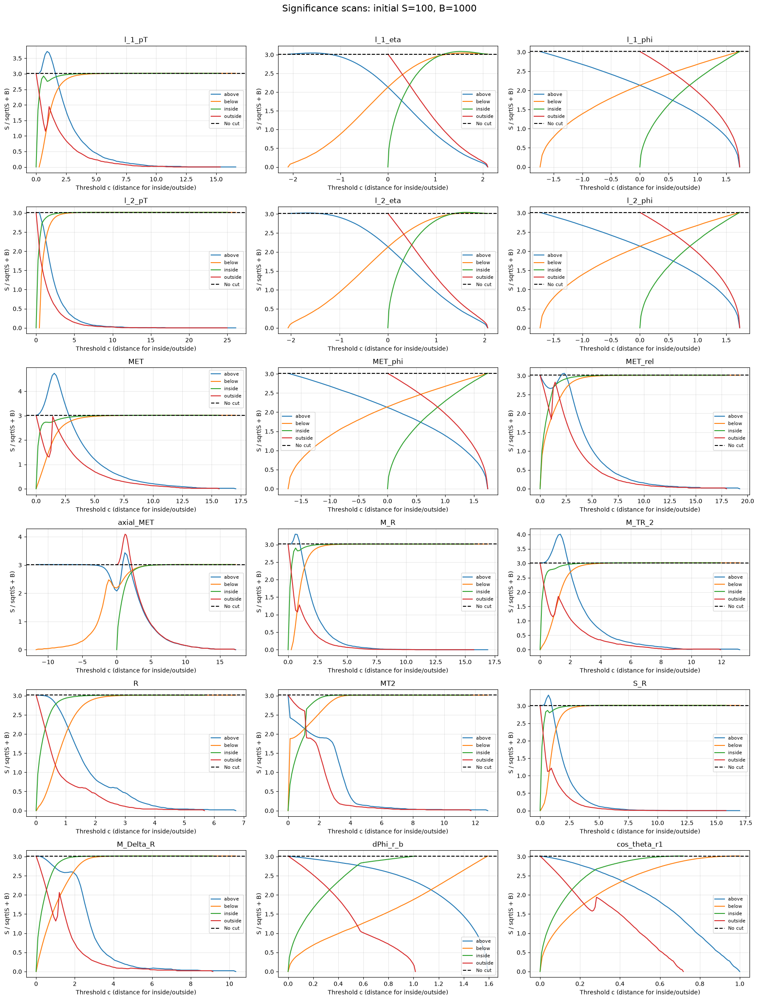

Initial signal: 100
Initial background: 1000
No-cut significance: 3.0151


Feature,Best tested cut,Signal efficiency,Background efficiency,Expected S after,Expected B after,Significance
MET,x > 1.551,0.3215,0.01391,32.15,13.91,4.737
axial_MET,|x - (0.08931)| > 1.218,0.2674,0.01597,26.74,15.97,4.091
M_TR_2,x > 1.342,0.369,0.04781,36.9,47.81,4.009
l_1_pT,x > 0.9172,0.6215,0.2171,62.15,217.1,3.719
S_R,x > 0.7127,0.7841,0.4828,78.41,482.8,3.31
M_R,x > 0.6037,0.8721,0.6128,87.21,612.8,3.296
l_1_eta,|x - (0.0008235)| < 1.509,0.9175,0.7916,91.75,791.6,3.087
MET_rel,x > 2.332,0.1429,0.007438,14.29,7.438,3.065
l_2_eta,|x - (0.002487)| < 1.624,0.9351,0.8511,93.51,851.1,3.043
l_2_pT,x < 12.36,1,1,100,1000,3.015


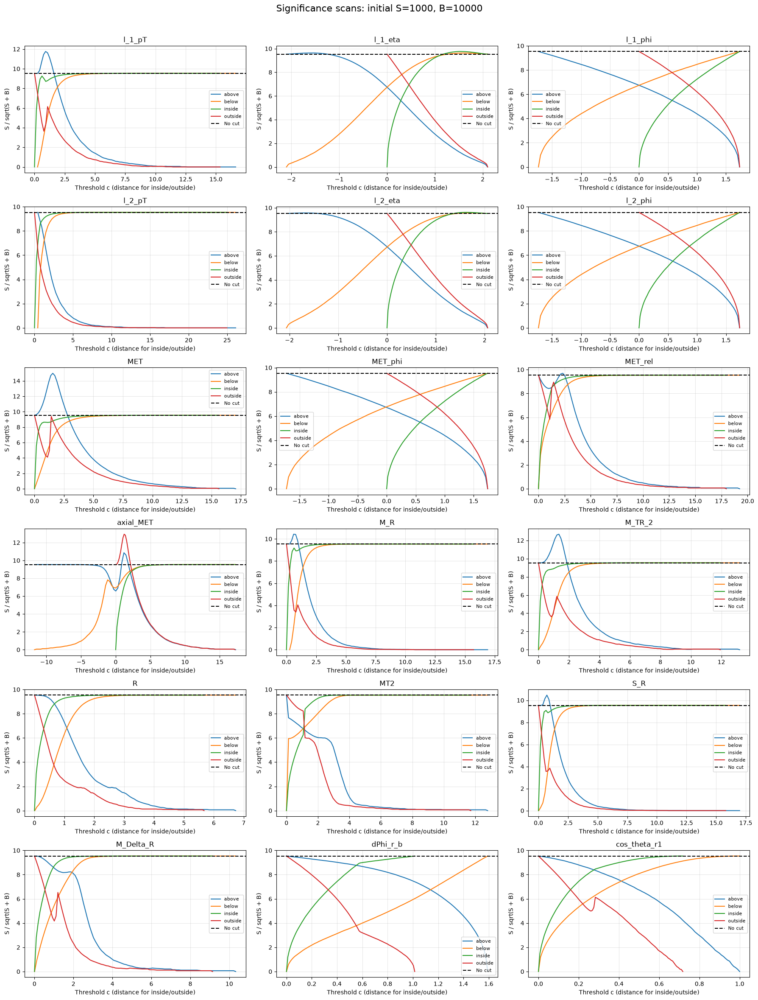

Initial signal: 1000
Initial background: 10000
No-cut significance: 9.5346


Feature,Best tested cut,Signal efficiency,Background efficiency,Expected S after,Expected B after,Significance
MET,x > 1.551,0.3215,0.01391,321.5,139.1,14.98
axial_MET,|x - (0.08931)| > 1.218,0.2674,0.01597,267.4,159.7,12.94
M_TR_2,x > 1.342,0.369,0.04781,369,478.1,12.68
l_1_pT,x > 0.9172,0.6215,0.2171,621.5,2171,11.76
S_R,x > 0.7127,0.7841,0.4828,784.1,4828,10.47
M_R,x > 0.6037,0.8721,0.6128,872.1,6128,10.42
l_1_eta,|x - (0.0008235)| < 1.509,0.9175,0.7916,917.5,7916,9.762
MET_rel,x > 2.332,0.1429,0.007438,142.9,74.38,9.692
l_2_eta,|x - (0.002487)| < 1.624,0.9351,0.8511,935.1,8511,9.622
l_2_pT,x < 12.36,1,1,1000,1e+04,9.535


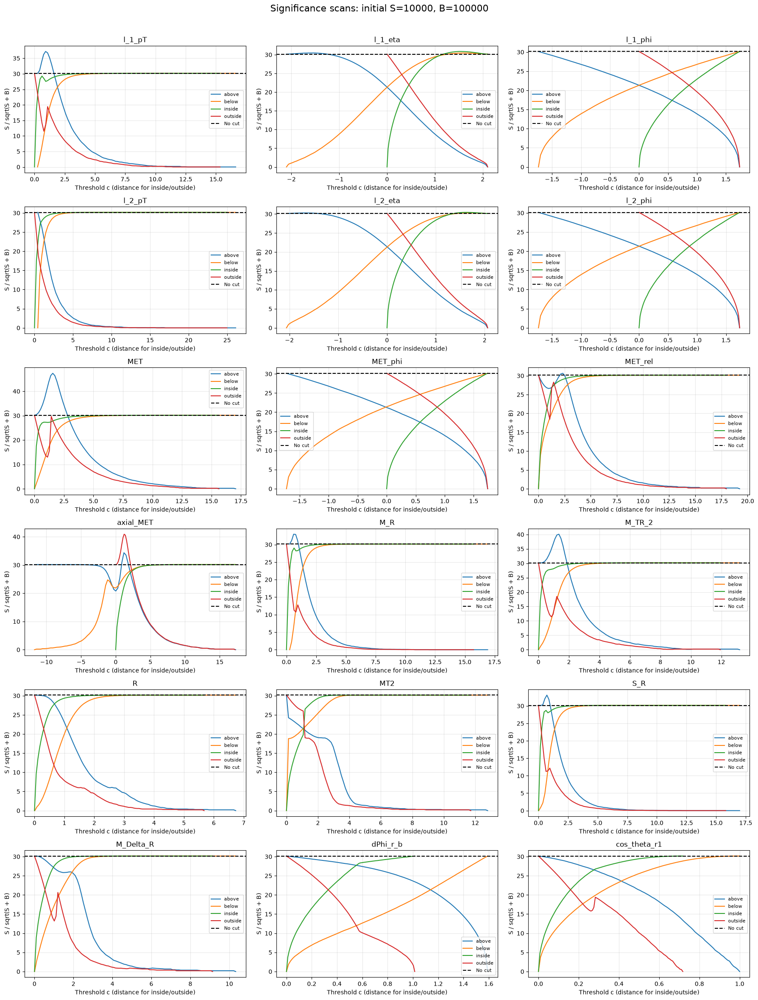

Initial signal: 10000
Initial background: 100000
No-cut significance: 30.1511


Feature,Best tested cut,Signal efficiency,Background efficiency,Expected S after,Expected B after,Significance
MET,x > 1.551,0.3215,0.01391,3215,1391,47.37
axial_MET,|x - (0.08931)| > 1.218,0.2674,0.01597,2674,1597,40.91
M_TR_2,x > 1.342,0.369,0.04781,3690,4781,40.09
l_1_pT,x > 0.9172,0.6215,0.2171,6215,2.171e+04,37.19
S_R,x > 0.7127,0.7841,0.4828,7841,4.828e+04,33.1
M_R,x > 0.6037,0.8721,0.6128,8721,6.128e+04,32.96
l_1_eta,|x - (0.0008235)| < 1.509,0.9175,0.7916,9175,7.916e+04,30.87
MET_rel,x > 2.332,0.1429,0.007438,1429,743.8,30.65
l_2_eta,|x - (0.002487)| < 1.624,0.9351,0.8511,9351,8.511e+04,30.43
l_2_pT,x < 12.36,1,1,1e+04,1e+05,30.15


In [75]:
#5.3 
# import numpy as np
# import matplotlib.pyplot as plt
# from tabulate import tabulate
from IPython.display import HTML, display

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

directions = ["above", "below", "inside", "outside"]

# Save results for later exercises.
significance_results = {}
best_cuts = {}


def calculate_significance(signal_after, background_after):
    total = signal_after + background_after

    significance = np.zeros_like(total, dtype=float)
    valid = total > 0

    significance[valid] = (
        signal_after[valid] / np.sqrt(total[valid])
    )

    return significance


for signal_before, background_before in scenarios:

    scenario = (signal_before, background_before)
    significance_results[scenario] = {}
    best_cuts[scenario] = {}

    baseline = signal_before / np.sqrt(
        signal_before + background_before
    )

    summary_rows = []

    fig, axes = plt.subplots(6, 3, figsize=(18, 24))
    axes = axes.flatten()

    for i, feature in enumerate(VarNames[1:]):

        significance_results[scenario][feature] = {}
        best = None

        for direction in directions:

            scan = efficiency_results[feature][direction]

            thresholds = scan["thresholds"]
            signal_efficiencies = np.asarray(
                scan["signal_efficiencies"]
            )
            background_efficiencies = np.asarray(
                scan["background_efficiencies"]
            )

            # Expected event counts after each cut.
            signal_after = signal_before * signal_efficiencies
            background_after = (
                background_before * background_efficiencies
            )

            significance = calculate_significance(
                signal_after, background_after
            )

            significance_results[scenario][feature][direction] = {
                "thresholds": thresholds,
                "significance": significance,
                "signal_after": signal_after,
                "background_after": background_after,
                "center": scan["center"]
            }

            axes[i].plot(
                thresholds,
                significance,
                label=direction
            )

            # Index of the highest significance in this scan.
            index = np.argmax(significance)

            # Compare the best results across all four directions.
            if best is None or significance[index] > best["significance"]:
                best = {
                    "direction": direction,
                    "threshold": float(thresholds[index]),
                    "center": float(scan["center"]),
                    "signal_efficiency": float(
                        signal_efficiencies[index]
                    ),
                    "background_efficiency": float(
                        background_efficiencies[index]
                    ),
                    "signal_after": float(signal_after[index]),
                    "background_after": float(background_after[index]),
                    "significance": float(significance[index])
                }

        best_cuts[scenario][feature] = best

        axes[i].axhline(
            baseline,
            color="black",
            linestyle="--",
            label="No cut"
        )

        axes[i].set_title(feature)
        axes[i].set_xlabel("Threshold c (distance for inside/outside)")
        axes[i].set_ylabel("S / sqrt(S + B)")
        axes[i].grid(alpha=0.3)
        axes[i].legend(fontsize=8)

        # Write the selected condition in a readable form.
        threshold = best["threshold"]
        center = best["center"]
        direction = best["direction"]

        if direction == "above":
            condition = f"x > {threshold:.4g}"
        elif direction == "below":
            condition = f"x < {threshold:.4g}"
        elif direction == "inside":
            condition = f"|x - ({center:.4g})| < {threshold:.4g}"
        else:
            condition = f"|x - ({center:.4g})| > {threshold:.4g}"

        summary_rows.append([
            feature,
            condition,
            best["signal_efficiency"],
            best["background_efficiency"],
            best["signal_after"],
            best["background_after"],
            best["significance"]
        ])

    fig.suptitle(
        f"Significance scans: initial S={signal_before}, "
        f"B={background_before}",
        fontsize=16
    )

    fig.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

    # Rank features by their best tested significance.
    summary_rows.sort(key=lambda row: row[-1], reverse=True)

    print(f"Initial signal: {signal_before}")
    print(f"Initial background: {background_before}")
    print(f"No-cut significance: {baseline:.4f}")

    display(HTML(tabulate(
        summary_rows,
        headers=[
            "Feature",
            "Best tested cut",
            "Signal efficiency",
            "Background efficiency",
            "Expected S after",
            "Expected B after",
            "Significance"
        ],
        tablefmt="html",
        floatfmt=".4g"
    )))

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [76]:
# import numpy as np
# from tabulate import tabulate
# from IPython.display import HTML, display

#this is helper function
def cut_mask(values, direction, threshold, center=0):
    values = np.asarray(values)

    if direction == "above":
        return values > threshold
    elif direction == "below":
        return values < threshold
    elif direction == "inside":
        return np.abs(values - center) < threshold
    elif direction == "outside":
        return np.abs(values - center) > threshold
    else:
        raise ValueError("Unknown cut direction")


def significance_value(signal, background):
    if signal + background == 0:
        return 0.0
    return signal / np.sqrt(signal + background)


def describe_cut(feature, cut):
    direction = cut["direction"]
    threshold = cut["threshold"]
    center = cut["center"]

    if direction == "above":
        return f"{feature} > {threshold:.4g}"
    elif direction == "below":
        return f"{feature} < {threshold:.4g}"
    elif direction == "inside":
        return f"|{feature} - ({center:.4g})| < {threshold:.4g}"
    else:
        return f"|{feature} - ({center:.4g})| > {threshold:.4g}"


def display_cutflow(rows, title):
    print(title)

    display(HTML(tabulate(
        rows,
        headers=[
            "Step",
            "Cut added",
            "Step signal efficiency",
            "Step background efficiency",
            "Cumulative signal efficiency",
            "Cumulative background efficiency",
            "Expected signal",
            "Expected background",
            "Significance"
        ],
        tablefmt="html",
        floatfmt=".4g"
    )))

In [77]:
#6.1
selected_features = {}

for scenario in scenarios:
    ranked = sorted(
        best_cuts[scenario],
        key=lambda feature: best_cuts[scenario][feature]["significance"],
        reverse=True
    )

    selected_features[scenario] = ranked[:3]

    rows = []

    for feature in selected_features[scenario]:
        cut = best_cuts[scenario][feature]

        rows.append([
            feature,
            describe_cut(feature, cut),
            cut["significance"]
        ])

    print(f"\nInitial S={scenario[0]}, B={scenario[1]}")

    display(HTML(tabulate(
        rows,
        headers=["Feature", "Selected individual cut", "Significance"],
        tablefmt="html",
        floatfmt=".4g"
    )))


Initial S=10, B=100


Feature,Selected individual cut,Significance
MET,MET > 1.551,1.498
axial_MET,|axial_MET - (0.08931)| > 1.218,1.294
M_TR_2,M_TR_2 > 1.342,1.268



Initial S=100, B=1000


Feature,Selected individual cut,Significance
MET,MET > 1.551,4.737
axial_MET,|axial_MET - (0.08931)| > 1.218,4.091
M_TR_2,M_TR_2 > 1.342,4.009



Initial S=1000, B=10000


Feature,Selected individual cut,Significance
MET,MET > 1.551,14.98
axial_MET,|axial_MET - (0.08931)| > 1.218,12.94
M_TR_2,M_TR_2 > 1.342,12.68



Initial S=10000, B=100000


Feature,Selected individual cut,Significance
MET,MET > 1.551,47.37
axial_MET,|axial_MET - (0.08931)| > 1.218,40.91
M_TR_2,M_TR_2 > 1.342,40.09


In [79]:
#6.2

def build_cutflow(scenario, feature_order, reoptimize=False):
    signal_before, background_before = scenario

    n_signal = len(df_sig)
    n_background = len(df_bkg)

    signal_survives = np.ones(n_signal, dtype=bool)
    background_survives = np.ones(n_background, dtype=bool)

    rows = [[
        0, "No cut",
        1.0, 1.0,
        1.0, 1.0,
        signal_before,
        background_before,
        significance_value(signal_before, background_before)
    ]]

    chosen_cuts = []

    for step, feature in enumerate(feature_order, start=1):

        previous_signal = signal_survives.sum()
        previous_background = background_survives.sum()

        # Values of events that survived all previous cuts.
        remaining_signal_values = (
            df_sig[feature].to_numpy()[signal_survives]
        )
        remaining_background_values = (
            df_bkg[feature].to_numpy()[background_survives]
        )

        if reoptimize:
            best_score = -np.inf
            chosen = None

            # Re-test all saved directions and thresholds
            # on the events surviving the preceding cuts.
            for direction, scan in efficiency_results[feature].items():
                center = scan["center"]

                for threshold in scan["thresholds"]:
                    signal_passes = cut_mask(
                        remaining_signal_values,
                        direction, threshold, center
                    ).sum()

                    background_passes = cut_mask(
                        remaining_background_values,
                        direction, threshold, center
                    ).sum()

                    expected_signal = (
                        signal_before * signal_passes / n_signal
                    )
                    expected_background = (
                        background_before * background_passes / n_background
                    )

                    score = significance_value(
                        expected_signal, expected_background
                    )

                    if score > best_score:
                        best_score = score
                        chosen = {
                            "direction": direction,
                            "threshold": float(threshold),
                            "center": float(center)
                        }

        else:
            chosen = best_cuts[scenario][feature].copy()

        # Combine the new condition with all earlier conditions.
        signal_survives &= cut_mask(
            df_sig[feature],
            chosen["direction"],
            chosen["threshold"],
            chosen["center"]
        )

        background_survives &= cut_mask(
            df_bkg[feature],
            chosen["direction"],
            chosen["threshold"],
            chosen["center"]
        )

        signal_count = signal_survives.sum()
        background_count = background_survives.sum()

        # Undefined if no events entered this step.
        step_signal_efficiency = (
            signal_count / previous_signal
            if previous_signal > 0 else np.nan
        )
        step_background_efficiency = (
            background_count / previous_background
            if previous_background > 0 else np.nan
        )

        cumulative_signal_efficiency = signal_count / n_signal
        cumulative_background_efficiency = background_count / n_background

        expected_signal = (
            signal_before * cumulative_signal_efficiency
        )
        expected_background = (
            background_before * cumulative_background_efficiency
        )

        score = significance_value(
            expected_signal, expected_background
        )

        rows.append([
            step,
            describe_cut(feature, chosen),
            step_signal_efficiency,
            step_background_efficiency,
            cumulative_signal_efficiency,
            cumulative_background_efficiency,
            expected_signal,
            expected_background,
            score
        ])

        chosen_cuts.append({"feature": feature, **chosen})

    return {
        "rows": rows,
        "cuts": chosen_cuts,
        "signal_mask": signal_survives,
        "background_mask": background_survives
    }


fixed_cutflows = {}

for scenario in scenarios:
    result = build_cutflow(
        scenario,
        selected_features[scenario],
        reoptimize=False
    )

    fixed_cutflows[scenario] = result

    display_cutflow(
        result["rows"],
        f"\nFixed cuts: initial S={scenario[0]}, B={scenario[1]}"
    )


Fixed cuts: initial S=10, B=100


Step,Cut added,Step signal efficiency,Step background efficiency,Cumulative signal efficiency,Cumulative background efficiency,Expected signal,Expected background,Significance
0,No cut,1,1,1,1,10,100,0.9535
1,MET > 1.551,0.3215,0.01391,0.3215,0.01391,3.215,1.391,1.498
2,|axial_MET - (0.08931)| > 1.218,0.7225,0.7339,0.2323,0.01021,2.323,1.021,1.27
3,M_TR_2 > 1.342,0.7027,0.7931,0.1632,0.008096,1.632,0.8096,1.045



Fixed cuts: initial S=100, B=1000


Step,Cut added,Step signal efficiency,Step background efficiency,Cumulative signal efficiency,Cumulative background efficiency,Expected signal,Expected background,Significance
0,No cut,1,1,1,1,100,1000,3.015
1,MET > 1.551,0.3215,0.01391,0.3215,0.01391,32.15,13.91,4.737
2,|axial_MET - (0.08931)| > 1.218,0.7225,0.7339,0.2323,0.01021,23.23,10.21,4.017
3,M_TR_2 > 1.342,0.7027,0.7931,0.1632,0.008096,16.32,8.096,3.303



Fixed cuts: initial S=1000, B=10000


Step,Cut added,Step signal efficiency,Step background efficiency,Cumulative signal efficiency,Cumulative background efficiency,Expected signal,Expected background,Significance
0,No cut,1,1,1,1,1000,1e+04,9.535
1,MET > 1.551,0.3215,0.01391,0.3215,0.01391,321.5,139.1,14.98
2,|axial_MET - (0.08931)| > 1.218,0.7225,0.7339,0.2323,0.01021,232.3,102.1,12.7
3,M_TR_2 > 1.342,0.7027,0.7931,0.1632,0.008096,163.2,80.96,10.45



Fixed cuts: initial S=10000, B=100000


Step,Cut added,Step signal efficiency,Step background efficiency,Cumulative signal efficiency,Cumulative background efficiency,Expected signal,Expected background,Significance
0,No cut,1,1,1,1,1e+04,1e+05,30.15
1,MET > 1.551,0.3215,0.01391,0.3215,0.01391,3215,1391,47.37
2,|axial_MET - (0.08931)| > 1.218,0.7225,0.7339,0.2323,0.01021,2323,1021,40.17
3,M_TR_2 > 1.342,0.7027,0.7931,0.1632,0.008096,1632,809.6,33.03


In [81]:
#6.3

optimized_cutflows = {}
comparison_rows = []

for scenario in scenarios:
    forward_order = selected_features[scenario]
    reverse_order = forward_order[::-1]

    forward = build_cutflow(
        scenario, forward_order, reoptimize=True
    )

    reverse = build_cutflow(
        scenario, reverse_order, reoptimize=True
    )

    optimized_cutflows[scenario] = {
        "forward": forward,
        "reverse": reverse
    }

    display_cutflow(
        forward["rows"],
        f"\nReoptimized forward: S={scenario[0]}, B={scenario[1]}"
    )

    display_cutflow(
        reverse["rows"],
        f"\nReoptimized reverse: S={scenario[0]}, B={scenario[1]}"
    )

    fixed_score = fixed_cutflows[scenario]["rows"][-1][-1]
    forward_score = forward["rows"][-1][-1]
    reverse_score = reverse["rows"][-1][-1]

    comparison_rows.append([
        scenario[0],
        scenario[1],
        fixed_score,
        forward_score,
        reverse_score
    ])

display(HTML(tabulate(
    comparison_rows,
    headers=[
        "Initial signal",
        "Initial background",
        "Fixed cuts: final significance",
        "Reoptimized forward: final significance",
        "Reoptimized reverse: final significance"
    ],
    tablefmt="html",
    floatfmt=".5g"
)))


Reoptimized forward: S=10, B=100


Step,Cut added,Step signal efficiency,Step background efficiency,Cumulative signal efficiency,Cumulative background efficiency,Expected signal,Expected background,Significance
0,No cut,1,1,1,1,10,100,0.9535
1,MET > 1.551,0.3215,0.01391,0.3215,0.01391,3.215,1.391,1.498
2,axial_MET > -11.72,1,1,0.3215,0.01391,3.215,1.391,1.498
3,M_TR_2 < 9.736,1,0.9997,0.3215,0.01391,3.215,1.391,1.498



Reoptimized reverse: S=10, B=100


Step,Cut added,Step signal efficiency,Step background efficiency,Cumulative signal efficiency,Cumulative background efficiency,Expected signal,Expected background,Significance
0,No cut,1,1,1,1,10,100,0.9535
1,M_TR_2 > 1.342,0.369,0.04781,0.369,0.04781,3.69,4.781,1.268
2,axial_MET > -11.72,1,1,0.369,0.04781,3.69,4.781,1.268
3,MET > 1.034,0.912,0.7563,0.3365,0.03616,3.365,3.616,1.274



Reoptimized forward: S=100, B=1000


Step,Cut added,Step signal efficiency,Step background efficiency,Cumulative signal efficiency,Cumulative background efficiency,Expected signal,Expected background,Significance
0,No cut,1,1,1,1,100,1000,3.015
1,MET > 1.551,0.3215,0.01391,0.3215,0.01391,32.15,13.91,4.737
2,axial_MET > -11.72,1,1,0.3215,0.01391,32.15,13.91,4.737
3,M_TR_2 < 9.736,1,0.9997,0.3215,0.01391,32.15,13.91,4.737



Reoptimized reverse: S=100, B=1000


Step,Cut added,Step signal efficiency,Step background efficiency,Cumulative signal efficiency,Cumulative background efficiency,Expected signal,Expected background,Significance
0,No cut,1,1,1,1,100,1000,3.015
1,M_TR_2 > 1.342,0.369,0.04781,0.369,0.04781,36.9,47.81,4.009
2,axial_MET > -11.72,1,1,0.369,0.04781,36.9,47.81,4.009
3,MET > 1.034,0.912,0.7563,0.3365,0.03616,33.65,36.16,4.028



Reoptimized forward: S=1000, B=10000


Step,Cut added,Step signal efficiency,Step background efficiency,Cumulative signal efficiency,Cumulative background efficiency,Expected signal,Expected background,Significance
0,No cut,1,1,1,1,1000,1e+04,9.535
1,MET > 1.551,0.3215,0.01391,0.3215,0.01391,321.5,139.1,14.98
2,axial_MET > -11.72,1,1,0.3215,0.01391,321.5,139.1,14.98
3,M_TR_2 < 9.736,1,0.9997,0.3215,0.01391,321.5,139.1,14.98



Reoptimized reverse: S=1000, B=10000


Step,Cut added,Step signal efficiency,Step background efficiency,Cumulative signal efficiency,Cumulative background efficiency,Expected signal,Expected background,Significance
0,No cut,1,1,1,1,1000,1e+04,9.535
1,M_TR_2 > 1.342,0.369,0.04781,0.369,0.04781,369,478.1,12.68
2,axial_MET > -11.72,1,1,0.369,0.04781,369,478.1,12.68
3,MET > 1.034,0.912,0.7563,0.3365,0.03616,336.5,361.6,12.74



Reoptimized forward: S=10000, B=100000


Step,Cut added,Step signal efficiency,Step background efficiency,Cumulative signal efficiency,Cumulative background efficiency,Expected signal,Expected background,Significance
0,No cut,1,1,1,1,1e+04,1e+05,30.15
1,MET > 1.551,0.3215,0.01391,0.3215,0.01391,3215,1391,47.37
2,axial_MET > -11.72,1,1,0.3215,0.01391,3215,1391,47.37
3,M_TR_2 < 9.736,1,0.9997,0.3215,0.01391,3215,1391,47.37



Reoptimized reverse: S=10000, B=100000


Step,Cut added,Step signal efficiency,Step background efficiency,Cumulative signal efficiency,Cumulative background efficiency,Expected signal,Expected background,Significance
0,No cut,1,1,1,1,1e+04,1e+05,30.15
1,M_TR_2 > 1.342,0.369,0.04781,0.369,0.04781,3690,4781,40.09
2,axial_MET > -11.72,1,1,0.369,0.04781,3690,4781,40.09
3,MET > 1.034,0.912,0.7563,0.3365,0.03616,3365,3616,40.28


Initial signal,Initial background,Fixed cuts: final significance,Reoptimized forward: final significance,Reoptimized reverse: final significance
10,100,1.0446,1.4981,1.2737
100,1000,3.3034,4.7374,4.0278
1000,10000,10.446,14.981,12.737
10000,100000,33.034,47.374,40.278


The observables may be correlated, so their individual efficiencies cannot generally be multiplied to obtain the combined efficiency. I calculated the combined efficiencies by counting events that passed all applied cuts.

Applying the same fixed cuts in a different order does not change the final selection because every event must satisfy all conditions. However, reoptimizing cuts after each selection can produce different thresholds and final significance values, because earlier cuts change the remaining data.

For the scenario with 10 initial signal events and 100 background events, the final significance was 1.0446 with fixed cuts, 1.4981 after forward reoptimization, and 1.2737 after reverse reoptimization. Forward reoptimization gave the highest final significance among these tested approaches. The difference between forward and reverse results shows that the order mattered when cuts were reoptimized after each selection.

## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



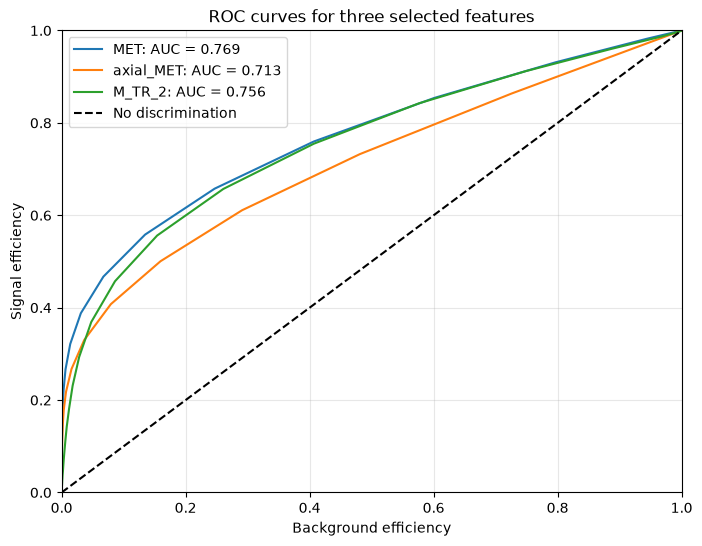

In [83]:
#7.1-7.2
def get_roc(signal_efficiencies, background_efficiencies, direction):
    tpr = np.array(signal_efficiencies)
    fpr = np.array(background_efficiencies)

    # Put points in order from rejecting all to accepting all.
    if direction in ["above", "outside"]:
        tpr = tpr[::-1]
        fpr = fpr[::-1]

    tpr = np.concatenate(([0], tpr, [1]))
    fpr = np.concatenate(([0], fpr, [1]))

    area = np.trapezoid(tpr, fpr)

    return fpr, tpr, area


def plot_roc(features, scenario):
    plt.figure(figsize=(8, 6))

    for feature in features:
        direction = best_cuts[scenario][feature]["direction"]
        result = efficiency_results[feature][direction]

        fpr, tpr, area = get_roc(
            result["signal_efficiencies"],
            result["background_efficiencies"],
            direction
        )

        plt.plot(
            fpr, tpr,
            label=f"{feature}: AUC = {area:.3f}"
        )

    plt.plot([0, 1], [0, 1], "k--", label="No discrimination")
    plt.xlabel("Background efficiency")
    plt.ylabel("Signal efficiency")
    plt.title("ROC curves for three selected features")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


scenario = (10, 100)
features = selected_features[scenario]

plot_roc(features, scenario)

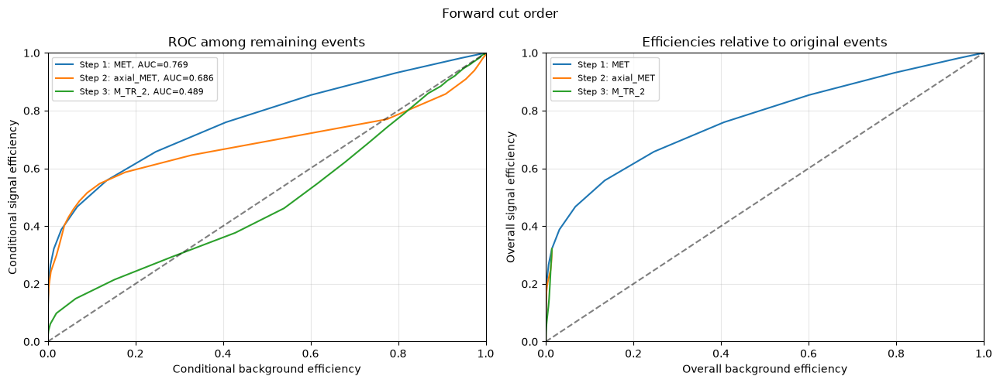

In [84]:
# 7.3
def plot_cut_sequence(cuts, title):
    signal_left = df_sig.copy()
    background_left = df_bkg.copy()

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    for i, cut in enumerate(cuts):
        if len(signal_left) == 0 or len(background_left) == 0:
            print("Cannot draw another ROC: one group has no events left.")
            break

        feature = cut["feature"]
        direction = cut["direction"]
        center = cut["center"]

        thresholds = efficiency_results[feature][direction]["thresholds"]

        sig_eff, bkg_eff = scan_efficiencies(
            signal_left,
            background_left,
            feature,
            thresholds,
            direction=direction,
            center=center
        )

        fpr, tpr, area = get_roc(sig_eff, bkg_eff, direction)

        # ROC relative to the events remaining before this step.
        axes[0].plot(
            fpr, tpr,
            label=f"Step {i + 1}: {feature}, AUC={area:.3f}"
        )

        # Include losses from the preceding cuts.
        overall_tpr = tpr * len(signal_left) / len(df_sig)
        overall_fpr = fpr * len(background_left) / len(df_bkg)

        axes[1].plot(
            overall_fpr,
            overall_tpr,
            label=f"Step {i + 1}: {feature}"
        )

        signal_mask = cut_mask(
            signal_left[feature],
            direction,
            cut["threshold"],
            center
        )

        background_mask = cut_mask(
            background_left[feature],
            direction,
            cut["threshold"],
            center
        )

        signal_left = signal_left[signal_mask]
        background_left = background_left[background_mask]

    axes[0].set_title("ROC among remaining events")
    axes[0].set_xlabel("Conditional background efficiency")
    axes[0].set_ylabel("Conditional signal efficiency")

    axes[1].set_title("Efficiencies relative to original events")
    axes[1].set_xlabel("Overall background efficiency")
    axes[1].set_ylabel("Overall signal efficiency")

    for ax in axes:
        ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


forward_cuts = optimized_cutflows[scenario]["forward"]["cuts"]

plot_cut_sequence(forward_cuts, "Forward cut order")

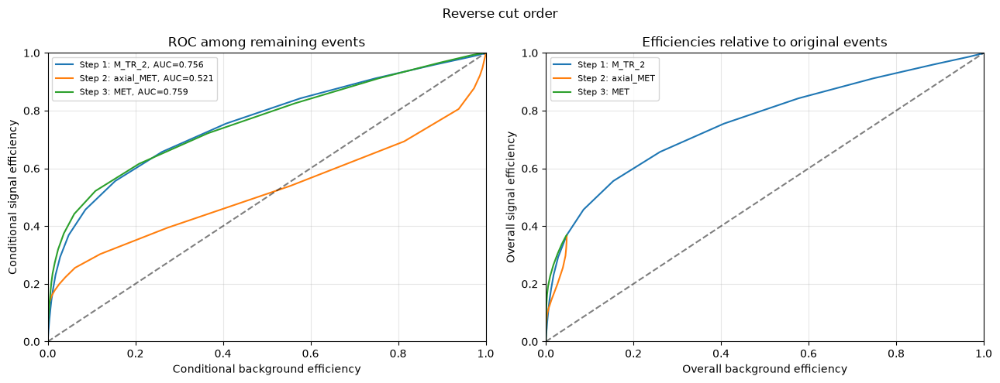

Forward final significance: 1.4981067180112915
Reverse final significance: 1.273710423536642


In [85]:
# 7.4
reverse_cuts = optimized_cutflows[scenario]["reverse"]["cuts"]

plot_cut_sequence(reverse_cuts, "Reverse cut order")

forward_score = optimized_cutflows[scenario]["forward"]["rows"][-1][-1]
reverse_score = optimized_cutflows[scenario]["reverse"]["rows"][-1][-1]

print("Forward final significance:", forward_score)
print("Reverse final significance:", reverse_score)

In [86]:
def apply_cuts(data, cuts):
    mask = np.ones(len(data), dtype=bool)

    for cut in cuts:
        mask &= cut_mask(
            data[cut["feature"]],
            cut["direction"],
            cut["threshold"],
            cut["center"]
        )

    return mask


fixed_cuts = fixed_cutflows[scenario]["cuts"]

for name, data in [("Signal", df_sig), ("Background", df_bkg)]:
    forward_mask = apply_cuts(data, fixed_cuts)
    reverse_mask = apply_cuts(data, fixed_cuts[::-1])

    print(name, "same selection:", np.array_equal(
        forward_mask, reverse_mask
    ))

Signal same selection: True
Background same selection: True


Forward reoptimization gave a significance of 1.4981, compared with 1.2737 for reverse reoptimization. In this test, forward order performed better because changing the order changed which events remained when later cuts were optimized.

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

In [87]:
# Exercise 8
features = VarNames[1:]

signal_values = df_sig[features].to_numpy()
background_values = df_bkg[features].to_numpy()

# Mean of each feature within each group.
signal_mean = signal_values.mean(axis=0)
background_mean = background_values.mean(axis=0)

difference = signal_mean - background_mean

# Between-class scatter matrix.
S_B = np.outer(difference, difference)

# Subtract each group's mean from its observations.
signal_centered = signal_values - signal_mean
background_centered = background_values - background_mean

# Within-class scatter matrix.
S_W = (
    signal_centered.T @ signal_centered
    + background_centered.T @ background_centered
)

# Solve S_W @ weights = difference.
weights = np.linalg.solve(S_W, difference)

# Rescale for convenient score values.
# This does not change the ranking of events.
weights = weights / np.linalg.norm(weights)

print("Between-class matrix shape:", S_B.shape)
print("Within-class matrix shape:", S_W.shape)

display(HTML(tabulate(
    list(zip(features, weights)),
    headers=["Feature", "Weight"],
    tablefmt="html",
    floatfmt=".4g"
)))

Between-class matrix shape: (18, 18)
Within-class matrix shape: (18, 18)


Feature,Weight
l_1_pT,0.3364
l_1_eta,0.000836
l_1_phi,0.0003121
l_2_pT,0.1477
l_2_eta,0.0005168
l_2_phi,0.0004016
MET,0.245
MET_phi,0.0004067
MET_rel,0.02072
axial_MET,0.03919


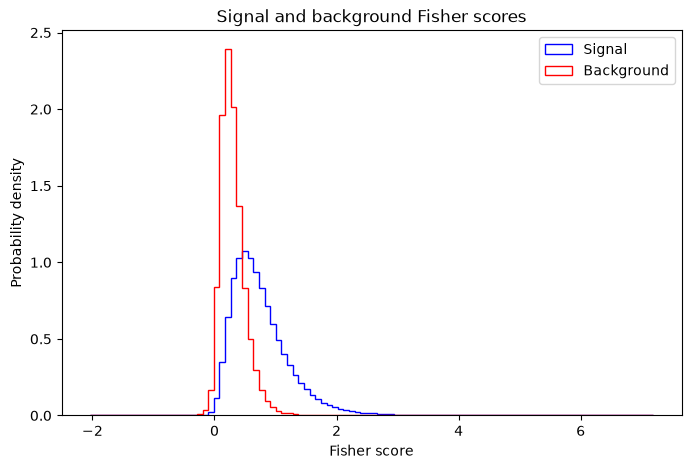

In [88]:
signal_scores = signal_values @ weights
background_scores = background_values @ weights

all_scores = np.concatenate([
    signal_scores, background_scores
])

edges = np.linspace(
    all_scores.min(),
    all_scores.max(),
    101
)

plt.figure(figsize=(8, 5))

plt.hist(
    signal_scores,
    bins=edges,
    density=True,
    histtype="step",
    color="blue",
    label="Signal"
)

plt.hist(
    background_scores,
    bins=edges,
    density=True,
    histtype="step",
    color="red",
    label="Background"
)

plt.xlabel("Fisher score")
plt.ylabel("Probability density")
plt.title("Signal and background Fisher scores")
plt.legend()
plt.show()

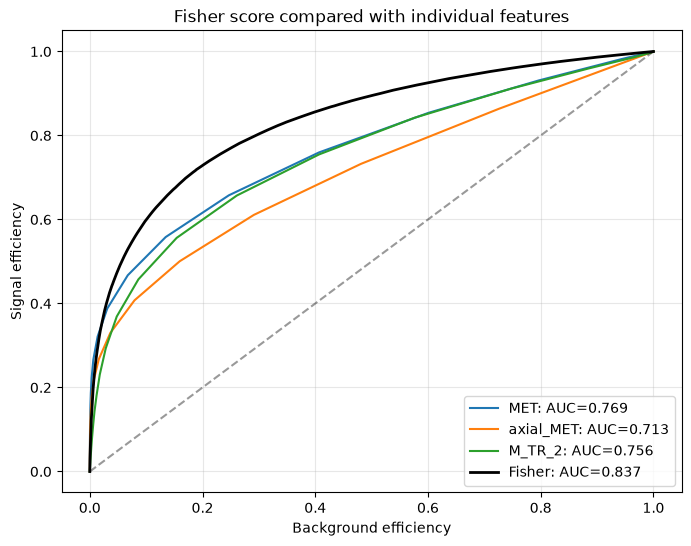

Approximate Fisher AUC: 0.8374784825740059


In [89]:
import pandas as pd

signal_score_data = pd.DataFrame({"score": signal_scores})
background_score_data = pd.DataFrame({"score": background_scores})

thresholds = np.unique(np.quantile(
    all_scores,
    np.linspace(0, 1, 501)
))

# Include thresholds that accept everything or reject everything.
thresholds = np.concatenate((
    [-np.inf], thresholds, [np.inf]
))

fisher_signal_eff, fisher_background_eff = scan_efficiencies(
    signal_score_data,
    background_score_data,
    "score",
    thresholds,
    direction="above"
)

fisher_fpr, fisher_tpr, fisher_auc = get_roc(
    fisher_signal_eff,
    fisher_background_eff,
    "above"
)

scenario = (10, 100)

plt.figure(figsize=(8, 6))

for feature in selected_features[scenario]:
    direction = best_cuts[scenario][feature]["direction"]
    scan = efficiency_results[feature][direction]

    fpr, tpr, area = get_roc(
        scan["signal_efficiencies"],
        scan["background_efficiencies"],
        direction
    )

    plt.plot(fpr, tpr, label=f"{feature}: AUC={area:.3f}")

plt.plot(
    fisher_fpr,
    fisher_tpr,
    color="black",
    linewidth=2,
    label=f"Fisher: AUC={fisher_auc:.3f}"
)

plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("Background efficiency")
plt.ylabel("Signal efficiency")
plt.title("Fisher score compared with individual features")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Approximate Fisher AUC:", fisher_auc)

In [90]:
fisher_results = {}
rows = []

for scenario in scenarios:
    signal_before, background_before = scenario

    signal_after = signal_before * np.asarray(fisher_signal_eff)
    background_after = (
        background_before * np.asarray(fisher_background_eff)
    )

    significance = calculate_significance(
        signal_after, background_after
    )

    index = np.argmax(significance)

    fisher_results[scenario] = {
        "threshold": thresholds[index],
        "signal_efficiency": fisher_signal_eff[index],
        "background_efficiency": fisher_background_eff[index],
        "significance": significance[index]
    }

    best_individual = max(
        cut["significance"]
        for cut in best_cuts[scenario].values()
    )

    forward_final = (
        optimized_cutflows[scenario]["forward"]["rows"][-1][-1]
    )
    reverse_final = (
        optimized_cutflows[scenario]["reverse"]["rows"][-1][-1]
    )

    rows.append([
        signal_before,
        background_before,
        thresholds[index],
        signal_after[index],
        background_after[index],
        significance[index],
        best_individual,
        forward_final,
        reverse_final
    ])

display(HTML(tabulate(
    rows,
    headers=[
        "Initial S",
        "Initial B",
        "Fisher threshold",
        "Expected S after",
        "Expected B after",
        "Fisher significance",
        "Best individual significance",
        "Forward final significance",
        "Reverse final significance"
    ],
    tablefmt="html",
    floatfmt=".5g"
)))

Initial S,Initial B,Fisher threshold,Expected S after,Expected B after,Fisher significance,Best individual significance,Forward final significance,Reverse final significance
10,100,0.68803,4.716,4.7597,1.532,1.4981,1.4981,1.2737
100,1000,0.68803,47.16,47.597,4.8448,4.7373,4.7374,4.0278
1000,10000,0.68803,471.6,475.97,15.32,14.981,14.981,12.737
10000,100000,0.68803,4716,4759.7,48.448,47.373,47.374,40.278


The Fisher score had an AUC of 0.837, higher than MET (0.769), axial_MET (0.713), and M_TR_2 (0.756). Combining the features improved separation in this sample.

For 10 expected signal and 100 background events, score > 0.68803 retained about 4.72 signal and 4.76 background events. Its significance was 1.532, slightly above forward selection (1.4981) and above reverse selection (1.2737).

The best threshold stayed the same across scenarios because the initial signal-to-background ratio stayed constant. These results use the same data used to calculate the weights and choose cuts, so separate test data are needed to check performance on new events.